# Flux: Sensible heat flux (H) (2004-2025)

# About this notebook

Overview of the sensible heat flux (`H`) of CH-LAE, 2004 to 2025, from the merged flux record
`30_FLUX_POST-PROCESSING_CHAIN/99_FPPC_MERGED_2004-2026.09`. This notebook computes and corrects
nothing; it describes what the flux chain produced.

**Sign convention and units.** `H` is positive when heat goes from the surface to the air (upward,
heating of the air) and negative when the air gives heat to the surface. By day `H` is mostly
positive; at night it is usually small and negative. Half-hourly values are in W m⁻². Annual and
monthly values are given as means in W m⁻² and as energy totals in MJ m⁻² (1 W m⁻² over 30 minutes
is 0.0018 MJ m⁻²).

**Columns used**

- `H_L3.1_L3.3_CUT_NONE_QCF_gfXG`: `H` after all quality tests (flag 0 and 1), without a USTAR
  filter (`CUT_NONE`), gap-filled with XGBoost. **The main series of the dataset** and the one used
  throughout unless stated otherwise
- `H_L3.1_L3.3_CUT_NONE_QCF`: the same before gap-filling, the measured records
- `FLAG_H_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED`: `0` measured, `1` gap-filled
- `H_L3.1_L3.3_CUT_NONE_QCF_gfMDS`: gap-filled with MDS, for comparison only
- `LE_L3.1_L3.3_CUT_NONE_QCF_gfXG`: the latent heat flux, for the Bowen ratio
- `FLAG_FLUX_SOURCE`: the flux run each half-hour is taken from, `75` the LI-7500 run, `72` the
  LI-7200 run
- `SW_IN_T1_47_1_MEASURED`, `TA_T1_47_1_HOMOGENIZED_MEASURED`, `DAYTIME`, `NIGHTTIME`: measured
  incoming shortwave radiation and air temperature, and the day and night flags

**One sonic anemometer, two flux runs.** `H` is the covariance of the vertical wind and the sonic
temperature, so it comes from the sonic anemometer alone; the gas analyser does not measure it. Its
instrument history is that of the sonic: a Gill HS-100 until 19 December 2019 and a Gill HS-50 from
then on, with the electronics unit of the HS-100 in use until 10 January 2020. The fieldbook has no
sonic record before 2016, so the model of the earlier years is not confirmed. The fluxes were
calculated in one EddyPro run per gas analyser, and each run also produces `H`. `FLAG_FLUX_SOURCE`
therefore applies to `H` as well, but it names the run, not the instrument that measured `H`. The
merged record takes `H` from the LI-7500 run until 2015 and from the LI-7200 run from 1 January
2016. The two runs differ in their settings and in the water vapour data that the humidity
correction of the sonic temperature uses, so the switch is kept as a marked boundary. *Sonic
anemometer phases* below lists all phases of the record, and *The two flux runs in parallel*
compares the two runs in 2016-2017.

::: {.callout-important title="Read the sonic change before comparing years across 2020"}

A difference between the years before and after December 2019 can come from the forest, from the
weather or from the change of sonic. The two sonics never measured in parallel, so a step between
them cannot be measured directly. Water or ice on the transducers produces large values of either
sign; these episodes were most frequent from 2016 to 2019, before the head was replaced, and their
values are removed and gap-filled. See *The years before and after the sonic change* below and the
`H` section of Level-3.2 on the documentation site.

:::

**Conventions used throughout**

- *Means and totals.* Annual and monthly values are means in W m⁻² and totals in MJ m⁻² over the
  gap-filled series, so the measured share of each year is reported before any statistic.
- *No USTAR filter.* `H` is not filtered for low turbulence (`CUT_NONE`), so nighttime records are
  removed only by the quality tests.
- *Measured records* are used only where the point is the measurement itself: coverage, extremes,
  the response to radiation, and the comparison of the two flux runs.
- *Before and after the change.* The years 2004-2019 are compared with the HS-50 years from 2020,
  the first full year of the new sonic.

**Timestamps.** The record is stored on `TIMESTAMP_MIDDLE` at 30 minutes in CET (UTC+1), so a
record labelled `13:15` is the average over `13:00` to `13:30`.

</br>

# Settings

In [1]:
# Columns of the merged flux record (30_FLUX_POST-PROCESSING_CHAIN/99).
varname = 'H_L3.1_L3.3_CUT_NONE_QCF_gfXG'  # the main series, used unless stated otherwise
varname_measured = 'H_L3.1_L3.3_CUT_NONE_QCF'  # the same before gap-filling
flagname = 'FLAG_H_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED'
varname_mds = 'H_L3.1_L3.3_CUT_NONE_QCF_gfMDS'
lename = 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG'  # latent heat flux, for the Bowen ratio
sourcename = 'FLAG_FLUX_SOURCE'
SOURCE_LEGEND = {75: 'LI-7500 run (IRGA75)', 72: 'LI-7200 run (IRGA72)'}
# Measured drivers in the same file, for the response to radiation and the extremes.
SW_IN = 'SW_IN_T1_47_1_MEASURED'
TA = 'TA_T1_47_1_HOMOGENIZED_MEASURED'
DAYTIME, NIGHTTIME = 'DAYTIME', 'NIGHTTIME'
COLUMNS = [varname, varname_measured, flagname, varname_mds, lename, sourcename, SW_IN, TA,
           DAYTIME, NIGHTTIME]

var = "H"  # name shown in plots
units = "W m-2"
units_sum = "MJ m-2"
WM2_TO_MJ = 1800 / 1e6  # W m-2 over one half-hour -> MJ m-2, i.e. 0.0018

# Period covered by the yearly statistics: the full years of the record. The record runs to
# 30 September 2026; 2026 is incomplete and appears only in the phase overview.
FIRST_YEAR = 2004
LAST_YEAR = 2025

# The phases of the H record. H comes from the sonic anemometer, so the phases follow the sonic
# and the flux run, not the gas analyser. Dates are the first day of each phase (TIMESTAMP_MIDDLE);
# a phase ends where the next one begins. The third value is the flux run in the merged record.
# Sources: docs/Instrumentation.md, docs/L3.2.md (H section) and the setup table in
# docs/Yearly_Notes.md.
PHASES = [
    ('2004-01-01', 'sonic before 2016, LI-7500 run', 75,
     'Gill sonic, model not in the fieldbook (the setup table gives an HS-50); H from the LI-7500 '
     'run; the measurement starts on 30 March 2004'),
    ('2016-01-01', 'HS-100, LI-7200 run', 72,
     'HS-100 (serial 000027), the first sonic in the fieldbook; H from the LI-7200 run; the '
     'LI-7500 run continues to 12 December 2017 and is compared below'),
    ('2019-01-10', 'no H in the record', 72,
     'both LI-7200 units defective, so the LI-7200 run has no data; the LI-7500 stand-in run is '
     'not used, and H is gap-filled although the sonic measured'),
    ('2019-03-20', 'HS-100, after the gap', 72,
     'HS-100 with the second LI-7200 unit'),
    ('2019-12-19', 'HS-50, HS-100 electronics', 72,
     'HS-50 (serial 000063) head on the electronics unit of the HS-100; the fieldbook rates the '
     'data as possibly not entirely accurate, H is kept'),
    ('2020-01-10', 'HS-50', 72,
     'HS-50 with its own electronics; raw data of 13 December 2021 to 7 February 2022 cannot be '
     'converted'),
]
RECORD_END = '2026-09-30 23:45'

# The two boundaries that can move H: the switch of the flux run and the change of sonic.
RUN_CHANGE = '2016-01-01'
SONIC_CHANGE = '2019-12-19'
SONIC_CHANGE_YEAR = 2020  # the first full year of the HS-50

# The two flux runs exist in parallel from the start of the LI-7200 to the removal of the LI-7500.
PARALLEL = ('2016-01-11', '2017-12-12')

# Analysis parameters.
N_EXTREMES = 10  # number of half-hours listed in the extremes tables
NIGHT_HIGH = 100.0  # W m-2; a measured nighttime H above this has no radiation to drive it
NIGHT_LOW = -150.0  # W m-2; a measured nighttime H below this is rare at this site
MIN_LABEL_DAYS = 100  # phases shorter than this are not labelled in the record plot
N_ADJACENT_YEARS = 3  # years on either side of the sonic change in the direct comparison
REFERENCE_START_YEAR = FIRST_YEAR  # reference period for all anomalies
REFERENCE_END_YEAR = LAST_YEAR
LIGHT_MONTHS = [6, 7, 8]  # full canopy, for the response to radiation
GROWING_MONTHS = [5, 6, 7, 8, 9]  # for the growing-season Bowen ratio
WINTER_MONTHS = [12, 1, 2]  # for the winter coverage, when wet and frozen sonic episodes occur
LIMITS = (-200.0, 800.0)  # the absolute limits of Level 3.2, W m-2, for the integrity check

# Input files. Data files live in the external (untracked) data folder, mirroring this repo.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILENAME = "99_FPPC_MERGED_2004-2026.09.parquet"
# The per-run records, for the parallel period only.
FILE_IRGA75 = r"IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet"
FILE_IRGA72 = r"IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet"

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import kendalltau, theilslopes

import diive as dv
from diive.core.plotting.cumulative import CumulativeYear
from diive.core.plotting.bar import LongtermAnomaliesYear

NOTEBOOK_START = datetime.now()
warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def per_year(s, how='mean'):
    """Aggregate `s` to one value per year, indexed by the year number instead of by a timestamp."""
    out = s.resample('YE').agg(how)
    out.index = out.index.year
    out.index.name = 'YEAR'
    return out


def per_year_month(s, how='mean', month_names=True):
    """Aggregate `s` to a table of YEAR (rows) by MONTH (columns)."""
    out = s.groupby([s.index.year, s.index.month]).agg(how).unstack()
    out.index.name = 'YEAR'
    if month_names:
        out.columns = [calendar.month_abbr[m] for m in out.columns]
    return out


def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure drawn with a layout engine makes room for a caption by itself. The figures pandas and
    diive build have no engine, and a caption placed in them lands on top of the tick labels. For
    those the figure is extended downwards by the height of the caption and every axes is moved up
    by the same amount, so the drawing keeps its size and position and the caption gets a free
    strip below it. `width` is the widest the caption may wrap, narrowed for a narrow figure.
    """
    # A fixed wrap width runs off the side of a narrow figure, so it is capped by how many
    # characters of this font size fit across the figure.
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure — {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12  # inches, one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)  # the old figure as a fraction of the new one
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


def window(tsmid):
    """The averaging window of a 30MIN record stored on TIMESTAMP_MIDDLE, as text."""
    start = tsmid - pd.Timedelta('15min')
    end = tsmid + pd.Timedelta('15min')
    return f"{start:%d %b %Y}, {start:%H:%M} to {end:%H:%M}"


def styled(data, caption, fmt="{:.1f}", subset=None, cmap="RdYlBu_r", axis=0, center=False):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table, so it is written as a sentence about what the table
    shows rather than as a title. `center` puts the midpoint of the colour scale at zero, and
    `axis=None` scales the colours across the whole table instead of column by column. The colour
    scale sets a text colour per cell, so the numbers stay readable in both the light and the dark
    version of the rendered page.
    """
    # Formats apply to numbers only, so text columns are dropped from the map. Without this a
    # table carrying a date or a label raises at render time, not at call time.
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def trend(yearly):
    """Theil-Sen slope per decade of a yearly series, with its 95 % interval and Kendall's tau.

    Theil-Sen rather than least squares because a single extreme year does not move it, and
    Kendall's tau because it tests a monotonic trend without assuming normal residuals.
    """
    years = yearly.index.to_numpy(dtype=float)
    values = yearly.to_numpy(dtype=float)
    slope, intercept, low, high = theilslopes(values, years, alpha=0.95)
    tau, pvalue = kendalltau(years, values)
    return dict(slope=slope * 10, low=low * 10, high=high * 10, tau=tau, pvalue=pvalue,
                fit=pd.Series(intercept + slope * years, index=yearly.index))


def year_axis(ax):
    """Integer year ticks. Matplotlib otherwise labels a numeric year axis with half-years."""
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    return ax


def to_mj(s):
    """Half-hourly H in W m-2 summed to MJ m-2 over whatever period `s` covers."""
    return s.sum() * WM2_TO_MJ


def phase_of(index):
    """The phase name of each timestamp in `index`."""
    starts = pd.to_datetime([p[0] for p in PHASES])
    pos = np.searchsorted(starts.to_numpy(), index.to_numpy(), side='right') - 1
    return pd.Series([PHASES[i][1] for i in pos], index=index)


def shade_phases(ax, alpha=0.08):
    """Shade the sonic phases behind a time axis and mark their boundaries."""
    colors = ['#1E88E5', '#43A047', '#9E9E9E', '#8E24AA', '#FB8C00', '#E53935']
    bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END)]
    for i, (start, end) in enumerate(zip(bounds[:-1], bounds[1:])):
        ax.axvspan(start, end, color=colors[i % len(colors)], alpha=alpha, lw=0)
        ax.axvline(start, color='#616161', lw=0.6, ls=':')


ERA_BEFORE = f"before the change, {FIRST_YEAR}-{SONIC_CHANGE_YEAR - 1}"
ERA_AFTER = f"HS-50, {SONIC_CHANGE_YEAR}-{LAST_YEAR}"
ERA_COLORS = {ERA_BEFORE: '#1E88E5', ERA_AFTER: '#43A047'}


def era(year):
    """The sonic era of a calendar year: before the change of December 2019, or the HS-50."""
    return ERA_BEFORE if year < SONIC_CHANGE_YEAR else ERA_AFTER


def run_of(year):
    """The flux run a calendar year of the merged record is taken from."""
    return 'LI-7500 run' if year < pd.Timestamp(RUN_CHANGE).year else 'LI-7200 run'


def mark_changes(ax, horizontal=False):
    """Mark the switch of the flux run (dotted) and the change of sonic (dashed) on a year axis.

    On a bar or line plot a year is centred on its number, so the boundary lies half a year before
    it. HeatmapXYZ draws year Y as the cell from Y to Y + 1, so there the boundary is the year itself.
    """
    line = ax.axhline if horizontal else ax.axvline
    offset = 0 if horizontal else 0.5
    # zorder above the heatmaps, which otherwise draw over the lines.
    line(pd.Timestamp(RUN_CHANGE).year - offset, color='black', lw=1.5, ls=':', zorder=200)
    line(SONIC_CHANGE_YEAR - offset, color='black', lw=1.5, ls='--', zorder=200)

</br>

# Load data

In [4]:
# Only the columns this notebook uses are read; the merged file has many more.
df_full = pd.read_parquet(Path(DATADIR) / FILENAME, columns=COLUMNS)
print(f"Columns: {df_full.shape[1]} of the merged file")
print(f"Range:   {df_full.index[0]} -> {df_full.index[-1]} ({len(df_full):,} records)")

# The yearly statistics cover FIRST_YEAR to LAST_YEAR; the phase overview uses the full record.
df = df_full.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
series = df[varname].copy()
series_measured = df[varname_measured].copy()
xlabel = f"{var} ({units})"
print(f"Kept {FIRST_YEAR}-{LAST_YEAR}: {len(df):,} records")

Columns: 10 of the merged file
Range:   2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)
Kept 2004-2025: 385,728 records


## Integrity checks

In [5]:
# The overview describes the record, so it starts by checking what everything below assumes: one
# continuous 30MIN record without duplicates, complete main series within the limits of Level 3.2,
# complete years, the gap-filled series equal to the measurement where there is one, and the flux
# run codes where the merge put them.
_issues = []
if df_full.index.name != 'TIMESTAMP_MIDDLE':
    _issues.append(f"index is {df_full.index.name}, not TIMESTAMP_MIDDLE")
if df_full.index.duplicated().any():
    _issues.append("duplicate timestamps")
if not (df_full.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("index gaps")
for _c in [varname, varname_mds, lename]:
    if df[_c].isna().any():
        _issues.append(f"{_c}: {int(df[_c].isna().sum())} missing values")
if ((series < LIMITS[0]) | (series > LIMITS[1])).any():
    _issues.append(f"values outside {LIMITS}")
_counts = series.groupby(series.index.year).size()
_short = {y: int(n) for y, n in _counts.items() if n != (17568 if calendar.isleap(y) else 17520)}
if _short:
    _issues.append(f"incomplete years: {_short}")
if set(df[flagname].unique()) - {0, 1}:
    _issues.append(f"unknown fill flags: {sorted(set(df[flagname].unique()))}")
# Measured records are exactly the records the fill flag marks as measured, and gap-filling
# leaves them unchanged.
if not (series_measured.notna() == df[flagname].eq(0)).all():
    _issues.append("fill flag and measured records disagree")
if not np.allclose(series[series_measured.notna()], series_measured.dropna()):
    _issues.append("gap-filled series differs from the measured records")
if not ((df_full[sourcename] == 75) == (df_full.index < RUN_CHANGE)).all():
    _issues.append("flux run codes not where the merge put them")

df_full.index.freq = '30min'  # the record is continuous, so its frequency can be declared
print(f"records: {len(df):,}   years: {FIRST_YEAR}-{LAST_YEAR}")
print(f"range:   {series.min():.1f} to {series.max():.1f} {units}")
assert not _issues, "the record is not what this overview assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

records: 385,728   years: 2004-2025
range:   -199.9 to 800.0 W m-2
Integrity checks passed.


## Derived series

In [6]:
# Daily means of the main series and of LE, with the measured share of each day, derived once.
# `daily` holds W m-2 for the means and MJ m-2 per day for the total.
daily = pd.DataFrame({
    'H': series.resample('D').mean(),
    'H total (MJ m-2)': series.resample('D').sum() * WM2_TO_MJ,
    'LE': df[lename].resample('D').mean(),
    'measured (%)': df[flagname].eq(0).resample('D').mean() * 100,
})
is_day = df[DAYTIME].eq(1)
print(f"Measured records: {series_measured.notna().sum():,} of {len(series):,} "
      f"({series_measured.notna().mean() * 100:.1f} %)")
daily.describe().round(2)

Measured records: 283,041 of 385,728 (73.4 %)


,H,H total (MJ m-2),LE,measured (%)
count,8036.00,8036.00,8036.00,8036.00
mean,35.48,3.07,53.45,73.38
std,37.99,3.28,45.48,21.03
min,-99.99,-8.64,-10.11,0.00
25%,5.45,0.47,15.73,68.75
50%,30.09,2.60,38.51,79.17
75%,63.02,5.44,86.14,85.42
max,174.68,15.09,225.53,100.00


</br>

# Sonic anemometer phases

The phases follow the sonic anemometer and the flux run, not the gas analyser. The sonic changed
once, on 19 December 2019, from the HS-100 to the HS-50. The flux run switched from the LI-7500
run to the LI-7200 run on 1 January 2016, with the same sonic. Changes of the gas analyser that do
not move `H` (a second LI-7200 unit, the moved inlet of 2023, the recalibrated unit of 2025) are not
phases here; a gas-analyser fault is a phase only where it removed `H` from the record.

## 📋 Table: the phases of the record

In [7]:
_bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END) + pd.Timedelta('15min')]
_rows = []
for (start, name, code_, note), end in zip(PHASES, _bounds[1:]):
    _sel = df_full.loc[start:end - pd.Timedelta('30min')]
    _meas = _sel[varname_measured].notna()
    _rows.append({
        'phase': name, 'from': f"{pd.Timestamp(start):%d %b %Y}",
        'to': f"{end - pd.Timedelta('1D'):%d %b %Y}",
        'days': (end - pd.Timestamp(start)).days, 'flux run in the product': SOURCE_LEGEND[code_],
        'measured (%)': 100 * _meas.mean(),
        'measured, day (%)': 100 * _meas[_sel[DAYTIME] == 1].mean(),
        'measured, night (%)': 100 * _meas[_sel[NIGHTTIME] == 1].mean(),
        'what changed': note})
phases = pd.DataFrame(_rows).set_index('phase')
display(styled(phases, caption="the phases of the H record with the flux run the merged product uses "
                               "in each, and the share of measured half-hours by day and by night "
                               "after all quality tests",
               fmt={'days': "{:.0f}", 'measured (%)': "{:.1f}", 'measured, day (%)': "{:.1f}",
                    'measured, night (%)': "{:.1f}"},
               subset=['measured (%)', 'measured, day (%)', 'measured, night (%)'], cmap='Blues'))

Table — the phases of the H record with the flux run the merged product uses in each, and the share
of measured half-hours by day and by night after all quality tests



,from,to,days,flux run in the product,measured (%),"measured, day (%)","measured, night (%)",what changed
phase,,,,,,,,
"sonic before 2016, LI-7500 run",01 Jan 2004,31 Dec 2015,4383,LI-7500 run (IRGA75),72.6,78.6,66.5,"Gill sonic, model not in the fieldbook (the setup table gives an HS-50); H from the LI-7500 run; the measurement starts on 30 March 2004"
"HS-100, LI-7200 run",01 Jan 2016,09 Jan 2019,1105,LI-7200 run (IRGA72),73.7,79.7,67.8,"HS-100 (serial 000027), the first sonic in the fieldbook; H from the LI-7200 run; the LI-7500 run continues to 12 December 2017 and is compared below"
no H in the record,10 Jan 2019,19 Mar 2019,69,LI-7200 run (IRGA72),0.7,0.9,0.5,"both LI-7200 units defective, so the LI-7200 run has no data; the LI-7500 stand-in run is not used, and H is gap-filled although the sonic measured"
"HS-100, after the gap",20 Mar 2019,18 Dec 2019,274,LI-7200 run (IRGA72),75.9,81.3,69.7,HS-100 with the second LI-7200 unit
"HS-50, HS-100 electronics",19 Dec 2019,09 Jan 2020,22,LI-7200 run (IRGA72),75.0,73.3,75.8,"HS-50 (serial 000063) head on the electronics unit of the HS-100; the fieldbook rates the data as possibly not entirely accurate, H is kept"
HS-50,10 Jan 2020,30 Sep 2026,2456,LI-7200 run (IRGA72),77.3,82.2,72.3,HS-50 with its own electronics; raw data of 13 December 2021 to 7 February 2022 cannot be converted


## 📊 Plot: the record and its phases

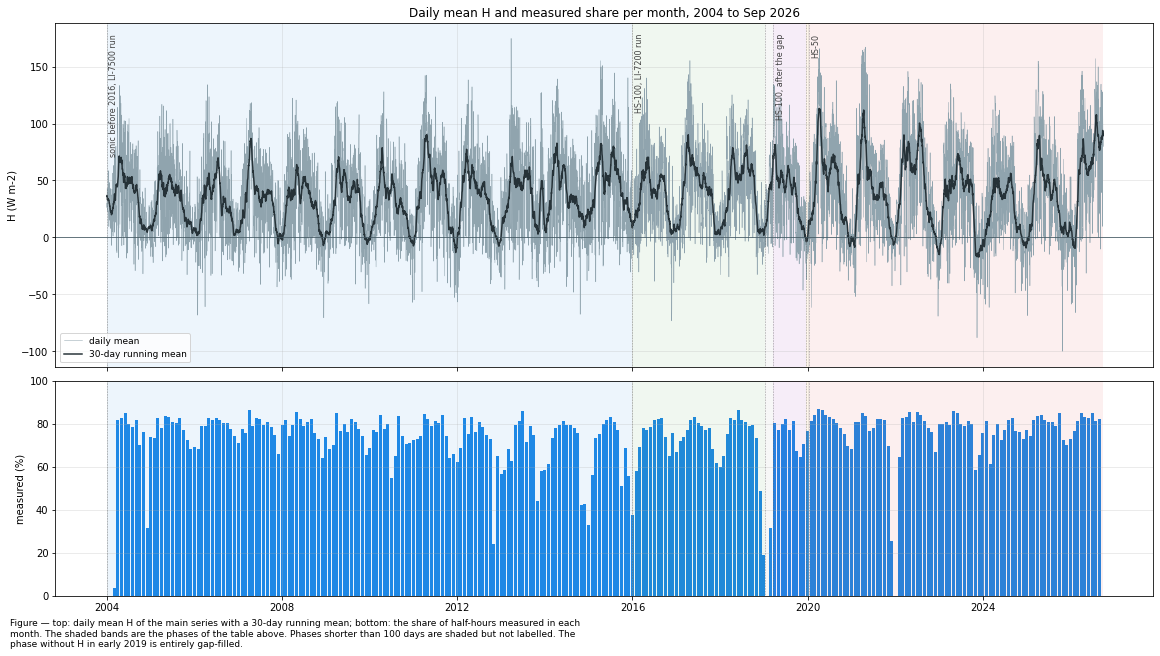

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9), dpi=72, sharex=True, layout="constrained",
                        height_ratios=[1.6, 1])
_d = df_full[varname].resample('D').mean()
axs[0].plot(_d.index, _d, color='#90A4AE', lw=0.5, label="daily mean")
axs[0].plot(_d.index, _d.rolling(30, center=True, min_periods=15).mean(), color='#263238', lw=1.5,
            label="30-day running mean")
axs[0].axhline(0, color='#455A64', lw=0.8)
axs[0].set_ylabel(f"H ({units})")
_m = df_full[varname_measured].notna().resample('MS').mean() * 100
axs[1].bar(_m.index, _m, width=25, color='#1E88E5')
axs[1].set_ylabel("measured (%)")
axs[1].set_ylim(0, 100)
for _ax in axs:
    shade_phases(_ax)
    _ax.grid(alpha=0.3)
_ymax = axs[0].get_ylim()[1]
_ends = [pd.Timestamp(p[0]) for p in PHASES[1:]] + [pd.Timestamp(RECORD_END)]
for (start, name, _, _), _end in zip(PHASES, _ends):
    if (_end - pd.Timestamp(start)).days < MIN_LABEL_DAYS:
        continue  # a short phase has no room for its label; it is listed in the table above
    axs[0].text(pd.Timestamp(start) + pd.Timedelta('20D'), _ymax * 0.95, name, rotation=90,
                va='top', ha='left', fontsize=8, color='#424242')
axs[0].legend(loc='lower left', fontsize=9)
axs[0].set_title(f"Daily mean H and measured share per month, {df_full.index[0]:%Y} to "
                 f"{df_full.index[-1]:%b %Y}")
figcap(fig, "top: daily mean H of the main series with a 30-day running mean; bottom: the share of "
            "half-hours measured in each month. The shaded bands are the phases of the table above. "
            f"Phases shorter than {MIN_LABEL_DAYS} days are shaded but not labelled. The phase without "
            f"H in early 2019 is entirely gap-filled.")
fig.show()

## 📋 Table: half-hours per flux run and year

In [9]:
_src = df_full[sourcename].groupby(df_full.index.year).value_counts().unstack(fill_value=0)
_src.columns = [SOURCE_LEGEND[c] for c in _src.columns]
_src.index.name = 'YEAR'
display(styled(_src, caption="half-hours per year by the flux run the merged record takes them from. "
                             "For H the code names the EddyPro run, not the instrument: both runs "
                             "use the same sonic anemometer",
               fmt="{:.0f}", cmap=None))

Table — half-hours per year by the flux run the merged record takes them from. For H the code names
the EddyPro run, not the instrument: both runs use the same sonic anemometer



,LI-7500 run (IRGA75),LI-7200 run (IRGA72)
YEAR,,
2004,17568,0
2005,17520,0
2006,17520,0
2007,17520,0
2008,17568,0
2009,17520,0
2010,17520,0
2011,17520,0
2012,17568,0


</br>

# Coverage

How much of each year was measured. Every mean and total below runs over the gap-filled series, so
this says how far each year rests on the measurement and how far on the model. The winter column
shows the months in which water and ice on the transducers remove most records.

## 📋 Table: coverage per year

In [10]:
_meas = series_measured.notna()
_winter = df.index.month.isin(WINTER_MONTHS)
coverage = pd.DataFrame({
    'sonic era': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'flux run': [run_of(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'measured (%)': per_year(_meas.astype(float), 'mean') * 100,
    'measured, day (%)': per_year(_meas.where(is_day).astype(float), 'mean') * 100,
    'measured, night (%)': per_year(_meas.where(~is_day).astype(float), 'mean') * 100,
    'measured, Dec-Feb (%)': per_year(_meas.where(_winter).astype(float), 'mean') * 100,
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
_filled = df[flagname].eq(1)
_blocks = _filled.ne(_filled.shift()).cumsum()[_filled]
_lengths = _filled[_filled].groupby(_blocks).size() / 48
_years = df.index[_filled].to_series().groupby(_blocks.to_numpy()).first().dt.year
coverage['longest gap (d)'] = pd.Series(_lengths.to_numpy(), index=_years.to_numpy()).groupby(level=0).max()
coverage.index.name = 'YEAR'
_pct = ['measured (%)', 'measured, day (%)', 'measured, night (%)', 'measured, Dec-Feb (%)']
display(styled(coverage, caption="measured share of H per year, by day, by night and in winter "
                                 "(December to February of the same calendar year), and the longest "
                                 "gap-filled run. 2004 is measured from 30 March",
               fmt={**{c: "{:.1f}" for c in _pct}, 'longest gap (d)': "{:.1f}"},
               subset=_pct, cmap='Blues'))

Table — measured share of H per year, by day, by night and in winter (December to February of the
same calendar year), and the longest gap-filled run. 2004 is measured from 30 March



,sonic era,flux run,measured (%),"measured, day (%)","measured, night (%)","measured, Dec-Feb (%)",longest gap (d)
YEAR,,,,,,,
2004,"before the change, 2004-2019",LI-7500 run,56.0,63.5,48.4,10.7,89.6
2005,"before the change, 2004-2019",LI-7500 run,78.2,83.4,72.9,72.0,3.3
2006,"before the change, 2004-2019",LI-7500 run,78.2,83.4,73.0,70.7,1.9
2007,"before the change, 2004-2019",LI-7500 run,77.9,83.6,72.2,71.4,1.8
2008,"before the change, 2004-2019",LI-7500 run,78.2,82.3,74.0,75.0,2.9
2009,"before the change, 2004-2019",LI-7500 run,76.0,81.2,70.8,69.4,2.4
2010,"before the change, 2004-2019",LI-7500 run,73.6,78.0,69.1,72.3,8.3
2011,"before the change, 2004-2019",LI-7500 run,76.4,82.7,70.2,70.5,2.3
2012,"before the change, 2004-2019",LI-7500 run,70.6,77.3,63.9,65.4,20.8


## 📊 Plot: measured share per year and month

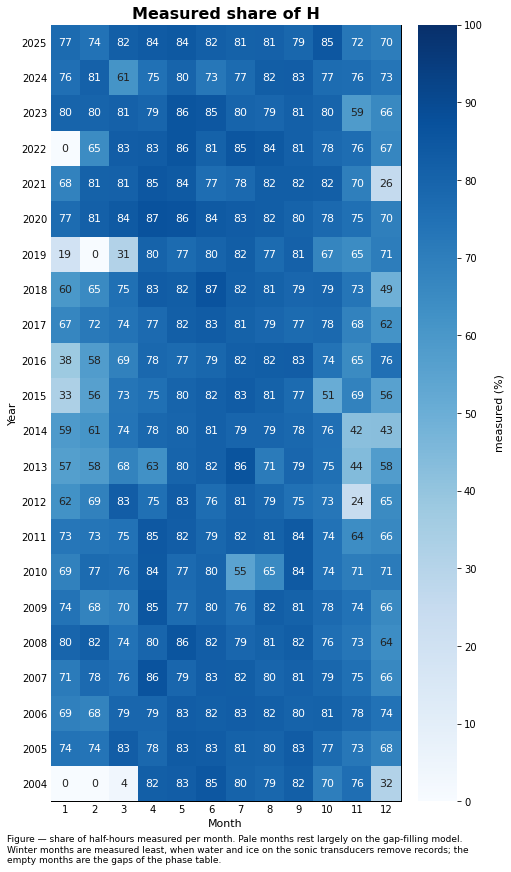

In [11]:
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
_meas_pct = (series_measured.notna().astype(float) * 100).rename("measured (%)")
dv.plotting.HeatmapYearMonth(series=_meas_pct, agg='mean').plot(
    ax=ax, cmap="Blues", vmin=0, vmax=100, zlabel="measured (%)", show_values=True, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Measured share of {var}", axlabel_fontsize=11,
                                         ticks_fontsize=10))
figcap(fig, "share of half-hours measured per month. Pale months rest largely on the gap-filling "
            "model. Winter months are measured least, when water and ice on the sonic transducers "
            "remove records; the empty months are the gaps of the phase table.")

</br>

# Annual means and totals

## 📋 Table: annual means and totals

In [12]:
# Annual means of the main series and of its MDS comparison, the energy total of the year, the
# means of day and night, and the summer mean. The total is the mean times the length of the year.
ym = per_year(series, 'mean')
annual = pd.DataFrame({
    'sonic era': [era(y) for y in ym.index],
    'flux run': [run_of(y) for y in ym.index],
    f"H ({units})": ym,
    f"H total ({units_sum})": per_year(series, to_mj),
    f"MDS ({units})": per_year(df[varname_mds], 'mean'),
    f"day ({units})": per_year(series.where(is_day), 'mean'),
    f"night ({units})": per_year(series.where(~is_day), 'mean'),
    f"Jun-Aug ({units})": per_year(series.where(series.index.month.isin(LIGHT_MONTHS)), 'mean'),
    "measured (%)": coverage['measured (%)'],
})
annual[f"MDS minus XGBoost ({units})"] = annual[f"MDS ({units})"] - annual[f"H ({units})"]
annual["rank (highest first)"] = annual[f"H ({units})"].rank(ascending=False).astype(int)
annual.index.name = 'YEAR'
_fmt = {c: "{:.1f}" for c in annual.columns}
_fmt[f"H total ({units_sum})"] = "{:.0f}"
_fmt[f"MDS minus XGBoost ({units})"] = "{:+.1f}"
_fmt["rank (highest first)"] = "{:.0f}"
display(styled(annual, caption=f"annual means of H in {units} and the annual energy total in "
                               f"{units_sum}: the main series (XGBoost), the MDS comparison and their "
                               f"difference, the means of daytime and nighttime half-hours and of "
                               f"June to August",
               fmt=_fmt, subset=[f"H ({units})"], cmap='RdYlBu_r'))

Table — annual means of H in W m-2 and the annual energy total in MJ m-2: the main series (XGBoost),
the MDS comparison and their difference, the means of daytime and nighttime half-hours and of June
to August



,sonic era,flux run,H (W m-2),H total (MJ m-2),MDS (W m-2),day (W m-2),night (W m-2),Jun-Aug (W m-2),measured (%),MDS minus XGBoost (W m-2),rank (highest first)
YEAR,,,,,,,,,,,
2004,"before the change, 2004-2019",LI-7500 run,35.0,1106,51.7,87.6,-17.3,44.8,56.0,+16.7,12
2005,"before the change, 2004-2019",LI-7500 run,31.5,994,32.1,79.1,-15.8,44.6,78.2,+0.6,17
2006,"before the change, 2004-2019",LI-7500 run,29.4,927,29.2,76.4,-17.3,47.2,78.2,-0.3,20
2007,"before the change, 2004-2019",LI-7500 run,32.1,1013,32.1,83.2,-18.6,35.4,77.9,+0.0,16
2008,"before the change, 2004-2019",LI-7500 run,29.6,936,29.6,79.2,-19.6,44.0,78.2,+0.0,19
2009,"before the change, 2004-2019",LI-7500 run,30.4,958,30.4,79.4,-18.3,44.8,76.0,-0.0,18
2010,"before the change, 2004-2019",LI-7500 run,29.0,915,29.0,75.5,-17.2,36.0,73.6,+0.0,21
2011,"before the change, 2004-2019",LI-7500 run,38.1,1201,38.3,96.2,-19.7,48.4,76.4,+0.2,7
2012,"before the change, 2004-2019",LI-7500 run,32.7,1033,32.0,84.8,-19.0,41.1,70.6,-0.7,14


## 📊 Plot: annual means

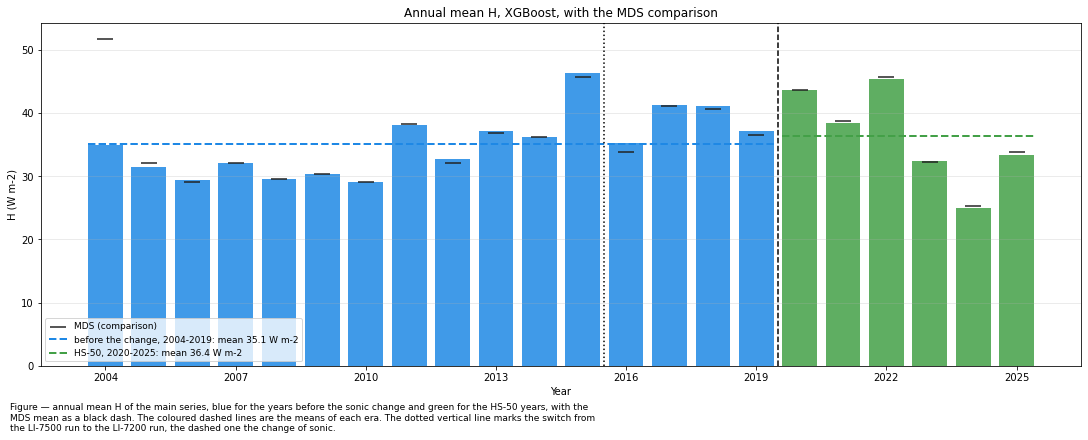

In [13]:
_colors = annual['sonic era'].map(ERA_COLORS)
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.bar(annual.index, annual[f"H ({units})"], color=_colors, alpha=0.85)
ax.scatter(annual.index, annual[f"MDS ({units})"], marker='_', s=250, color='#212121', zorder=5,
           label="MDS (comparison)")
for _name, _c in ERA_COLORS.items():
    _x = annual.loc[annual['sonic era'] == _name, f"H ({units})"]
    ax.hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color=_c, lw=2, ls='--',
              label=f"{_name}: mean {_x.mean():.1f} {units}")
ax.axhline(0, color='#455A64', lw=0.8)
mark_changes(ax)
ax.set_xlabel("Year")
ax.set_ylabel(f"H ({units})")
ax.set_title("Annual mean H, XGBoost, with the MDS comparison")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, loc='lower left')
year_axis(ax)
figcap(fig, "annual mean H of the main series, blue for the years before the sonic change and green "
            "for the HS-50 years, with the MDS mean as a black dash. The coloured dashed lines are "
            "the means of each era. The dotted vertical line marks the switch from the LI-7500 run "
            "to the LI-7200 run, the dashed one the change of sonic.")
fig.show()

</br>

# The years before and after the sonic change

The HS-100 was replaced by the HS-50 on 19 December 2019, and the two never measured in parallel.
The table compares the annual values of three periods: the LI-7500 run, the HS-100 in the LI-7200
run, and the HS-50. The first two share the sonic history up to 2019 and differ in the flux run;
the last two share the flux run and differ in the sonic. The weather of the periods differs as
well, so a difference is a hint, not a proof.

## 📋 Table: annual values per period

In [14]:
# Bowen ratio of each year: the ratio of the annual sums of H and LE.
_bowen_year = per_year(series, 'sum') / per_year(df[lename], 'sum')
_cols = [f"H ({units})", f"H total ({units_sum})", f"day ({units})", f"night ({units})",
         f"Jun-Aug ({units})", "measured (%)"]
_vals = annual[_cols].assign(**{"Bowen ratio": _bowen_year})
_first72 = pd.Timestamp(RUN_CHANGE).year
_groups = {f"LI-7500 run, {FIRST_YEAR}-{_first72 - 1}": _vals.loc[:_first72 - 1],
           f"HS-100, LI-7200 run, {_first72}-{SONIC_CHANGE_YEAR - 1}": _vals.loc[_first72:SONIC_CHANGE_YEAR - 1],
           ERA_BEFORE: _vals.loc[:SONIC_CHANGE_YEAR - 1],
           ERA_AFTER: _vals.loc[SONIC_CHANGE_YEAR:]}
periods = pd.concat({'mean': pd.DataFrame({k: v.mean() for k, v in _groups.items()}).T,
                     'SD between years': pd.DataFrame({k: v.std() for k, v in _groups.items()}).T,
                     'years': pd.DataFrame({k: v.count() for k, v in _groups.items()}).T}, axis=1)
periods.loc['difference (HS-50 minus before)', 'mean'] = (periods.loc[ERA_AFTER, 'mean']
                                                          - periods.loc[ERA_BEFORE, 'mean']).to_numpy()
_fmt = {c: ("{:.0f}" if c[0] == 'years' or 'total' in c[1] else
            "{:.2f}" if c[1] == "Bowen ratio" else "{:.1f}") for c in periods.columns}
display(styled(periods, caption=f"means of the annual values over the years of each period, with the "
                                f"standard deviation between years: annual mean H and its total, the "
                                f"daytime, nighttime and June to August means, the measured share and "
                                f"the Bowen ratio of the annual sums. LE, the denominator of the "
                                f"Bowen ratio, comes from the gas analyser and changes with it in 2016",
               fmt=_fmt, cmap=None))

Table — means of the annual values over the years of each period, with the standard deviation
between years: annual mean H and its total, the daytime, nighttime and June to August means, the
measured share and the Bowen ratio of the annual sums. LE, the denominator of the Bowen ratio, comes
from the gas analyser and changes with it in 2016



## 📊 Plot: summer H in the years next to the change

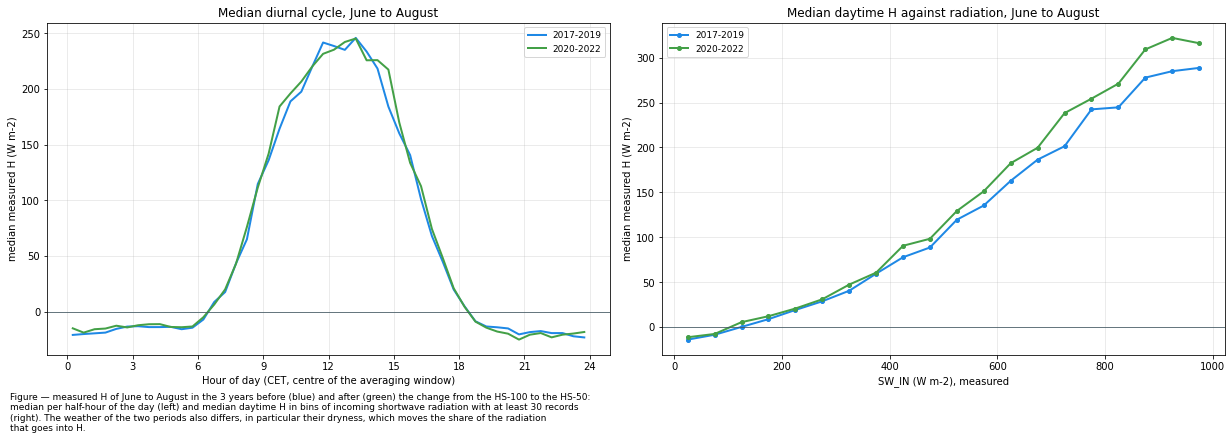

In [15]:
# The years just before and just after the change, measured records of June to August only. The
# left panel shows the mean day, the right one H against radiation, which removes the part of the
# difference that comes from sunnier or cloudier summers.
_before = list(range(SONIC_CHANGE_YEAR - N_ADJACENT_YEARS, SONIC_CHANGE_YEAR))
_after = list(range(SONIC_CHANGE_YEAR, SONIC_CHANGE_YEAR + N_ADJACENT_YEARS))
_summer = df[[varname_measured, SW_IN, DAYTIME]][df.index.month.isin(LIGHT_MONTHS)]
_bins = np.arange(0, 1001, 50)
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
for _years, _c in ((_before, ERA_COLORS[ERA_BEFORE]), (_after, ERA_COLORS[ERA_AFTER])):
    _sel = _summer[_summer.index.year.isin(_years)]
    _label = f"{_years[0]}-{_years[-1]}"
    _hourly = _sel[varname_measured].groupby(_sel.index.hour + _sel.index.minute / 60).median()
    axs[0].plot(_hourly.index, _hourly, color=_c, lw=2, label=_label)
    _day = _sel[_sel[DAYTIME].eq(1)].dropna()
    _g = _day.groupby(pd.cut(_day[SW_IN], _bins), observed=True)[varname_measured]
    _med = _g.median()[_g.count() >= 30]
    axs[1].plot([i.mid for i in _med.index], _med.to_numpy(), color=_c, lw=2, marker='o', ms=4,
                label=_label)
axs[0].set_xticks(range(0, 25, 3))
axs[0].set_xlabel("Hour of day (CET, centre of the averaging window)")
axs[0].set_title("Median diurnal cycle, June to August")
axs[1].set_xlabel("SW_IN (W m-2), measured")
axs[1].set_title("Median daytime H against radiation, June to August")
for _ax in axs:
    _ax.set_ylabel(f"median measured H ({units})")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, f"measured H of June to August in the {N_ADJACENT_YEARS} years before (blue) and after "
            f"(green) the change from the HS-100 to the HS-50: median per half-hour of the day (left) "
            f"and median daytime H in bins of incoming shortwave radiation with at least 30 records "
            f"(right). The weather of the two periods also differs, in particular their dryness, "
            f"which moves the share of the radiation that goes into H.")
fig.show()

</br>

# Seasonality

## Monthly means per year

### 📋 Table: monthly means per year

In [16]:
monthly_mean = per_year_month(series, 'mean')
monthly_by_number = per_year_month(series, 'mean', month_names=False)
monthly_total_by_number = per_year_month(series, to_mj, month_names=False)
display(styled(monthly_mean, caption=f"monthly mean H ({units}), one row per year. The colour scale "
                                     f"runs over the whole table",
               fmt="{:.0f}", cmap='RdYlBu_r', axis=None))

Table — monthly mean H (W m-2), one row per year. The colour scale runs over the whole table



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,33,22,43,67,55,47,47,40,36,12,8,8
2005,10,23,52,48,42,52,39,43,35,15,14,4
2006,4,12,31,49,41,51,69,21,33,21,13,7
2007,7,20,44,86,43,42,32,33,40,30,6,2
2008,4,37,39,38,55,44,48,40,27,24,5,-5
2009,5,16,27,68,46,52,35,47,40,27,4,-4
2010,7,17,43,76,35,38,48,22,34,22,9,-3
2011,3,27,56,89,71,42,50,54,49,21,5,-10
2012,5,50,75,46,58,42,38,44,31,8,1,-4


## Climatology per calendar month

### 📋 Table: climatology per calendar month

In [17]:
_by_month = monthly_by_number
climatology = pd.DataFrame({
    f"mean ({units})": _by_month.mean(),
    f"mean total ({units_sum})": monthly_total_by_number.mean(),
    "SD between years": _by_month.std(),
    "highest": _by_month.max(),
    "in": _by_month.idxmax(),
    "lowest": _by_month.min(),
    "in ": _by_month.idxmin(),
    "mean, before": _by_month.loc[:SONIC_CHANGE_YEAR - 1].mean(),
    "mean, HS-50": _by_month.loc[SONIC_CHANGE_YEAR:].mean(),
})
climatology["HS-50 minus before"] = climatology["mean, HS-50"] - climatology["mean, before"]
climatology.index = [calendar.month_abbr[m] for m in climatology.index]
climatology.index.name = 'MONTH'
_fmt = {c: "{:.1f}" for c in climatology.columns}
_fmt[f"mean total ({units_sum})"] = "{:.0f}"
_fmt["HS-50 minus before"] = "{:+.1f}"
_fmt["in"] = _fmt["in "] = "{:.0f}"
display(styled(climatology, caption=f"each calendar month across {FIRST_YEAR}-{LAST_YEAR}: its mean H in "
                                    f"{units} and its mean total in {units_sum}, the spread between "
                                    f"years, the years of the highest and lowest mean, and the mean "
                                    f"over the years before the sonic change ({ERA_BEFORE.split(', ')[1]}) "
                                    f"and of the HS-50 ({ERA_AFTER.split(', ')[1]})",
               fmt=_fmt, subset=["HS-50 minus before"], cmap='RdBu_r', center=True))

Table — each calendar month across 2004-2025: its mean H in W m-2 and its mean total in MJ m-2, the
spread between years, the years of the highest and lowest mean, and the mean over the years before
the sonic change (2004-2019) and of the HS-50 (2020-2025)



,mean (W m-2),mean total (MJ m-2),SD between years,highest,in,lowest,in,"mean, before","mean, HS-50",HS-50 minus before
MONTH,,,,,,,,,,
Jan,8.4,23,8.6,32.8,2004,-3.3,2024,10.6,2.7,-7.9
Feb,27.1,66,10.7,49.6,2012,12.1,2006,26.8,27.9,+1.2
Mar,51.1,137,15.0,81.9,2022,27.4,2009,48.8,57.3,+8.5
Apr,69.1,179,19.4,107.4,2020,37.5,2008,65.4,79.0,+13.5
May,52.5,141,9.5,71.3,2011,34.6,2010,51.3,55.9,+4.6
Jun,48.3,125,7.8,69.2,2023,34.8,2024,47.5,50.2,+2.7
Jul,49.6,133,15.4,90.3,2022,27.6,2014,47.7,54.5,+6.7
Aug,47.2,126,13.9,76.0,2022,21.2,2006,45.0,53.2,+8.2
Sep,40.2,104,9.5,63.2,2018,27.0,2025,40.6,39.3,-1.3


## Mean annual cycle

### 📊 Plot: mean annual cycle of daily H, before and after the sonic change

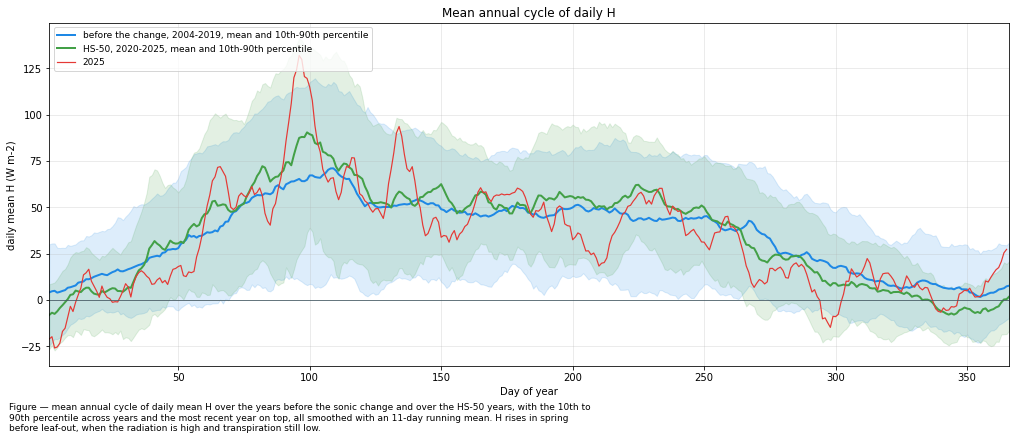

In [18]:
# Daily means per day of year, smoothed with an 11-day running mean, for the years of each era.
fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
_sm = lambda s: s.rolling(11, center=True, min_periods=3).mean()
for _name, _sel in ((ERA_BEFORE, daily.loc[:str(SONIC_CHANGE_YEAR - 1)]),
                    (ERA_AFTER, daily.loc[str(SONIC_CHANGE_YEAR):])):
    _c = ERA_COLORS[_name]
    _g = _sel['H'].groupby(_sel.index.dayofyear)
    ax.fill_between(_g.mean().index, _sm(_g.quantile(0.1)), _sm(_g.quantile(0.9)), color=_c, alpha=0.15)
    ax.plot(_g.mean().index, _sm(_g.mean()), color=_c, lw=2,
            label=f"{_name}, mean and 10th-90th percentile")
_last = daily.loc[str(LAST_YEAR), 'H']
ax.plot(_last.index.dayofyear, _sm(_last), color='#E53935', lw=1.2, label=str(LAST_YEAR))
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xlim(1, 366)
ax.set_xlabel("Day of year")
ax.set_ylabel(f"daily mean H ({units})")
ax.set_title("Mean annual cycle of daily H")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper left')
figcap(fig, "mean annual cycle of daily mean H over the years before the sonic change and over the "
            "HS-50 years, with the 10th to 90th percentile across years and the most recent year on "
            "top, all smoothed with an 11-day running mean. H rises in spring before leaf-out, when "
            "the radiation is high and transpiration still low.")
fig.show()

## Mean diurnal cycle per month

### 📊 Plot: mean diurnal cycle per month, before and after the sonic change

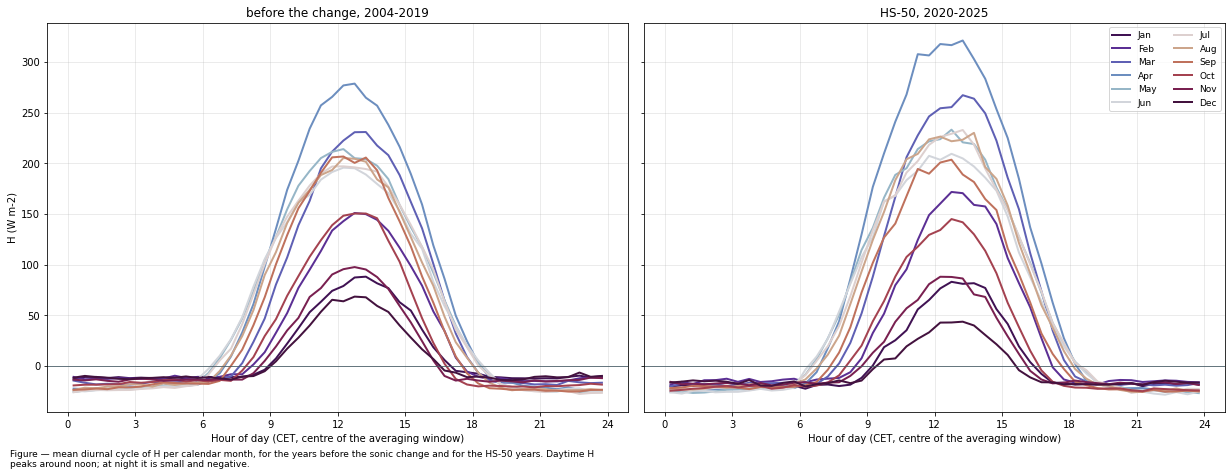

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_colors = plt.get_cmap('twilight_shifted')(np.linspace(0.05, 0.95, 12))
for _ax, (_name, _s) in zip(axs, ((ERA_BEFORE, series.loc[:str(SONIC_CHANGE_YEAR - 1)]),
                                  (ERA_AFTER, series.loc[str(SONIC_CHANGE_YEAR):]))):
    _diurnal = _s.groupby([_s.index.month, _s.index.hour + _s.index.minute / 60]).mean().unstack(0)
    for _i, _month in enumerate(_diurnal.columns):
        _ax.plot(_diurnal.index, _diurnal[_month], color=_colors[_i], lw=2, label=calendar.month_abbr[_month])
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_xticks(range(0, 25, 3))
    _ax.set_xlabel("Hour of day (CET, centre of the averaging window)")
    _ax.set_title(_name)
    _ax.grid(alpha=0.3)
axs[0].set_ylabel(xlabel)
axs[1].legend(ncol=2, fontsize=9)
figcap(fig, "mean diurnal cycle of H per calendar month, for the years before the sonic change and "
            "for the HS-50 years. Daytime H peaks around noon; at night it is small and negative.")
fig.show()

## Month by hour

### 📊 Plot: month by hour, and the difference between the years before and after the change

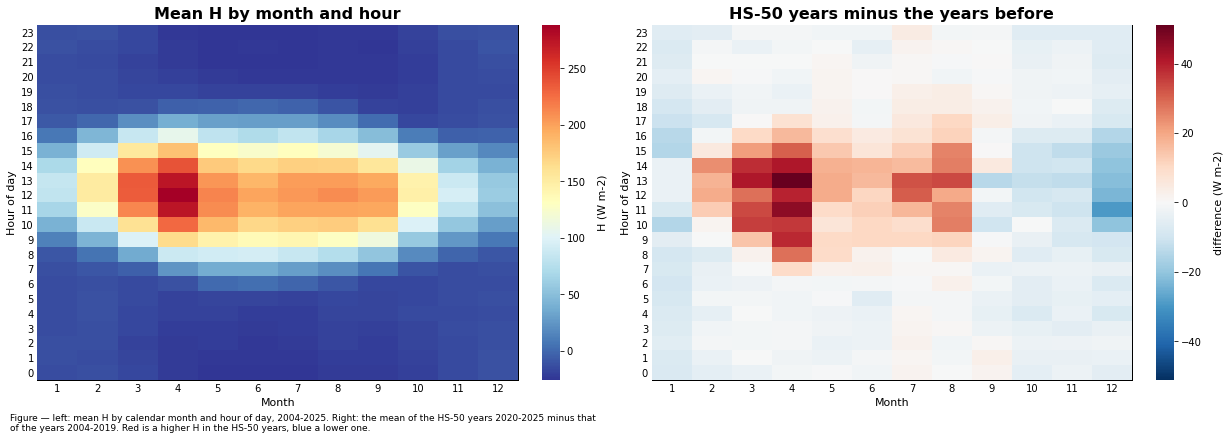

In [20]:
def _by_month_hour(s):
    """Mean of `s` per calendar month and hour, in the long form HeatmapXYZ expects."""
    frame = pd.DataFrame({'MONTH': s.index.month, 'HOUR': s.index.hour, 'z': s.to_numpy()})
    return frame.groupby(['MONTH', 'HOUR'], as_index=False)['z'].mean()


_all = _by_month_hour(series)
_diff = _by_month_hour(series.loc[str(SONIC_CHANGE_YEAR):])
_diff['z'] = _diff['z'].to_numpy() - _by_month_hour(series.loc[:str(SONIC_CHANGE_YEAR - 1)])['z'].to_numpy()
_absmax = _diff['z'].abs().max()
_style = dict(axlabel_fontsize=11, ticks_fontsize=10)
fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_all['MONTH'], y=_all['HOUR'], z=_all['z']).plot(
    ax=axs[0], xlabel="Month", ylabel="Hour of day", zlabel=xlabel, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Mean {var} by month and hour", **_style))
dv.plotting.HeatmapXYZ(x=_diff['MONTH'], y=_diff['HOUR'], z=_diff['z']).plot(
    ax=axs[1], cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, xlabel="Month", ylabel="Hour of day",
    zlabel=f"difference ({units})", cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="HS-50 years minus the years before", **_style))
figcap(fig, f"left: mean H by calendar month and hour of day, {FIRST_YEAR}-{LAST_YEAR}. Right: the mean "
            f"of the HS-50 years {ERA_AFTER.split(', ')[1]} minus that of the years "
            f"{ERA_BEFORE.split(', ')[1]}. Red is a higher H in the HS-50 years, blue a lower one.")

</br>

# Extremes

From the measured records only: a half-hourly extreme of the gap-filled series is a model value.
The values are bounded by the absolute limits of Level 3.2 (see Settings). Values of wet and
freezing episodes that lie inside the limits can remain, so each half-hour is listed with the
radiation and air temperature beside it, and the last table counts the large values at night.

## 📋 Table: the largest positive half-hours

In [21]:
def _ranked_halfhours(_label, _ranked):
    _table = pd.DataFrame({"averaging window": [window(_t) for _t in _ranked.index],
                           f"H ({units})": _ranked.to_numpy(),
                           f"SW_IN ({units})": df.loc[_ranked.index, SW_IN].to_numpy(),
                           "TA (°C)": df.loc[_ranked.index, TA].to_numpy(),
                           f"LE ({units})": df.loc[_ranked.index, lename].to_numpy(),
                           "phase": phase_of(_ranked.index).to_numpy()},
                          index=range(1, len(_ranked) + 1))
    _table.index.name = "rank"
    display(styled(_table, caption=f"the {len(_ranked)} measured half-hours of {_label} H in "
                                   f"{FIRST_YEAR}-{LAST_YEAR}, with the measured radiation and air "
                                   f"temperature, LE of the main series and the phase of the record",
                   fmt={f"H ({units})": "{:.1f}", f"SW_IN ({units})": "{:.0f}", "TA (°C)": "{:.1f}",
                        f"LE ({units})": "{:.0f}"},
                   subset=[f"H ({units})"], cmap='Reds' if _label == 'the largest positive' else 'Blues_r'))


_ranked_halfhours('the largest positive', series_measured.nlargest(N_EXTREMES))

Table — the 10 measured half-hours of the largest positive H in 2004-2025, with the measured
radiation and air temperature, LE of the main series and the phase of the record



,averaging window,H (W m-2),SW_IN (W m-2),TA (°C),LE (W m-2),phase
rank,,,,,,
1,"06 Apr 2015, 12:30 to 13:00",800.0,618,5.6,144,"sonic before 2016, LI-7500 run"
2,"14 Oct 2015, 04:30 to 05:00",799.8,0,3.4,53,"sonic before 2016, LI-7500 run"
3,"28 Mar 2021, 13:00 to 13:30",794.0,808,10.4,198,HS-50
4,"26 Jan 2015, 14:30 to 15:00",793.1,36,-3.1,17,"sonic before 2016, LI-7500 run"
5,"15 Feb 2016, 12:00 to 12:30",788.5,76,0.2,2,"HS-100, LI-7200 run"
6,"23 Mar 2022, 12:00 to 12:30",788.1,754,12.7,242,HS-50
7,"21 Apr 2021, 11:00 to 11:30",788.1,861,12.7,130,HS-50
8,"23 Mar 2021, 10:30 to 11:00",786.0,695,4.4,78,HS-50
9,"01 Apr 2013, 10:30 to 11:00",784.4,749,-0.3,126,"sonic before 2016, LI-7500 run"


## 📋 Table: the largest negative half-hours

In [22]:
_ranked_halfhours('the largest negative', series_measured.nsmallest(N_EXTREMES))

Table — the 10 measured half-hours of the largest negative H in 2004-2025, with the measured
radiation and air temperature, LE of the main series and the phase of the record



,averaging window,H (W m-2),SW_IN (W m-2),TA (°C),LE (W m-2),phase
rank,,,,,,
1,"04 Mar 2018, 11:00 to 11:30",-199.9,647,5.4,36,"HS-100, LI-7200 run"
2,"23 Jan 2015, 17:30 to 18:00",-199.9,0,-1.2,33,"sonic before 2016, LI-7500 run"
3,"28 Oct 2016, 13:30 to 14:00",-199.7,259,7.5,42,"HS-100, LI-7200 run"
4,"22 Jan 2024, 16:00 to 16:30",-199.7,6,3.5,-36,HS-50
5,"28 Dec 2011, 20:00 to 20:30",-199.6,0,-0.5,8,"sonic before 2016, LI-7500 run"
6,"16 Oct 2015, 18:00 to 18:30",-199.6,0,3.6,10,"sonic before 2016, LI-7500 run"
7,"04 Sep 2016, 15:30 to 16:00",-199.4,87,18.7,56,"HS-100, LI-7200 run"
8,"11 Dec 2015, 17:00 to 17:30",-199.4,0,4.2,10,"sonic before 2016, LI-7500 run"
9,"16 Apr 2016, 08:00 to 08:30",-199.3,32,8.1,7,"HS-100, LI-7200 run"


## 📋 Table: extremes per year

In [23]:
_g = series_measured.groupby(series_measured.index.year)
_imax, _imin = _g.idxmax(), _g.idxmin()
_peaks = pd.DataFrame({'sonic era': [era(y) for y in _imax.index],
                       f"maximum ({units})": series_measured.loc[_imax.to_numpy()].to_numpy(),
                       'window of the maximum': [window(t) for t in _imax.to_numpy()],
                       f"99th percentile ({units})": _g.quantile(0.99),
                       f"minimum ({units})": series_measured.loc[_imin.to_numpy()].to_numpy(),
                       'window of the minimum': [window(t) for t in _imin.to_numpy()],
                       f"1st percentile ({units})": _g.quantile(0.01)}, index=_imax.index)
_peaks.index.name = 'YEAR'
display(styled(_peaks, caption="the largest and the most negative measured half-hour of each year, "
                               "with the 99th and 1st percentiles of the measured records, which are "
                               "less sensitive to a single half-hour",
               fmt={c: "{:.1f}" for c in _peaks.columns if units in c},
               subset=[f"99th percentile ({units})", f"1st percentile ({units})"], cmap='RdYlBu_r'))

Table — the largest and the most negative measured half-hour of each year, with the 99th and 1st
percentiles of the measured records, which are less sensitive to a single half-hour



,sonic era,maximum (W m-2),window of the maximum,99th percentile (W m-2),minimum (W m-2),window of the minimum,1st percentile (W m-2)
YEAR,,,,,,,
2004,"before the change, 2004-2019",672.5,"21 Apr 2004, 11:30 to 12:00",435.2,-184.0,"25 May 2004, 03:30 to 04:00",-104.8
2005,"before the change, 2004-2019",645.4,"04 Apr 2005, 13:00 to 13:30",375.4,-196.3,"10 Jul 2005, 13:30 to 14:00",-91.4
2006,"before the change, 2004-2019",642.7,"31 Jul 2006, 13:30 to 14:00",392.5,-197.4,"15 Apr 2006, 16:00 to 16:30",-114.9
2007,"before the change, 2004-2019",722.1,"03 Apr 2007, 13:00 to 13:30",414.5,-195.0,"19 Jun 2007, 23:00 to 23:30",-119.0
2008,"before the change, 2004-2019",733.7,"08 May 2008, 11:30 to 12:00",392.5,-196.6,"14 Dec 2008, 12:00 to 12:30",-111.8
2009,"before the change, 2004-2019",744.2,"22 Apr 2009, 13:30 to 14:00",410.7,-196.9,"24 Nov 2009, 08:00 to 08:30",-105.1
2010,"before the change, 2004-2019",648.8,"29 Apr 2010, 13:00 to 13:30",406.6,-198.2,"13 May 2010, 09:30 to 10:00",-111.1
2011,"before the change, 2004-2019",753.9,"08 Apr 2011, 12:00 to 12:30",460.3,-199.6,"28 Dec 2011, 20:00 to 20:30",-126.6
2012,"before the change, 2004-2019",779.7,"15 Jan 2012, 13:30 to 14:00",455.7,-197.4,"31 Oct 2012, 12:30 to 13:00",-122.9


## 📋 Table: large nighttime values per year

In [24]:
# At night there is no radiation to heat the surface, so H is small and mostly negative. A large
# positive value at night has no energy source and points at water or ice on the sonic transducers;
# a large negative value is possible in strong wind over a cold canopy but rare.
_night = series_measured[df[NIGHTTIME].eq(1)]
_gy = _night.groupby(_night.index.year)
night_large = pd.DataFrame({
    'sonic era': [era(y) for y in _gy.size().index],
    'flux run': [run_of(y) for y in _gy.size().index],
    'measured nighttime half-hours': _gy.count(),
    f"above {NIGHT_HIGH:.0f} {units}": _gy.apply(lambda s: int((s > NIGHT_HIGH).sum())),
    f"below {NIGHT_LOW:.0f} {units}": _gy.apply(lambda s: int((s < NIGHT_LOW).sum())),
    f"99.9th percentile ({units})": _gy.quantile(0.999),
    f"0.1th percentile ({units})": _gy.quantile(0.001),
})
night_large.index.name = 'YEAR'
display(styled(night_large, caption=f"measured nighttime H per year: the number of half-hours above "
                                    f"{NIGHT_HIGH:.0f} and below {NIGHT_LOW:.0f} {units}, and the extreme "
                                    f"percentiles. These values passed all quality tests. A large positive "
                                    f"value at night has no radiation to drive it",
               fmt={'measured nighttime half-hours': "{:.0f}", f"above {NIGHT_HIGH:.0f} {units}": "{:.0f}",
                    f"below {NIGHT_LOW:.0f} {units}": "{:.0f}", f"99.9th percentile ({units})": "{:.1f}",
                    f"0.1th percentile ({units})": "{:.1f}"},
               subset=[f"above {NIGHT_HIGH:.0f} {units}"], cmap='Reds'))

Table — measured nighttime H per year: the number of half-hours above 100 and below -150 W m-2, and
the extreme percentiles. These values passed all quality tests. A large positive value at night has
no radiation to drive it



,sonic era,flux run,measured nighttime half-hours,above 100 W m-2,below -150 W m-2,99.9th percentile (W m-2),0.1th percentile (W m-2)
YEAR,,,,,,,
2004,"before the change, 2004-2019",LI-7500 run,4273,4,5,99.1,-157.1
2005,"before the change, 2004-2019",LI-7500 run,6409,0,6,76.8,-147.6
2006,"before the change, 2004-2019",LI-7500 run,6413,10,18,108.6,-169.9
2007,"before the change, 2004-2019",LI-7500 run,6346,3,19,85.1,-171.6
2008,"before the change, 2004-2019",LI-7500 run,6527,8,18,111.2,-174.4
2009,"before the change, 2004-2019",LI-7500 run,6222,7,10,96.9,-153.1
2010,"before the change, 2004-2019",LI-7500 run,6077,32,23,129.7,-180.2
2011,"before the change, 2004-2019",LI-7500 run,6171,36,43,169.4,-193.2
2012,"before the change, 2004-2019",LI-7500 run,5637,46,30,202.8,-181.0


</br>

# Responses

H is driven by the available energy, and the share of it that goes into H rather than into LE
depends on how much water the canopy transpires. The response to radiation uses measured records
only; the Bowen ratio uses the gap-filled series of both fluxes.

## Response to radiation

### 📊 Plot: daytime H against incoming shortwave radiation in summer

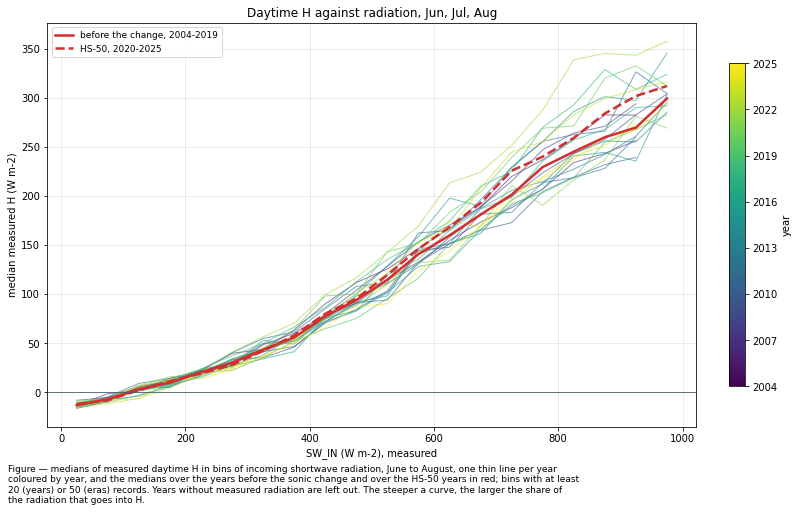

In [25]:
_bins_light = np.arange(0, 1001, 50)
_day = df[[varname_measured, SW_IN]].where(df[DAYTIME].eq(1)).dropna()
_day = _day[_day.index.month.isin(LIGHT_MONTHS)]
_cmap = plt.get_cmap('viridis')


def _binned(d, bins, min_count):
    """Median measured H per bin of SW_IN, for bins holding at least `min_count` records."""
    _g = d.groupby(pd.cut(d[SW_IN], bins), observed=True)[varname_measured]
    _med = _g.median()[_g.count() >= min_count]
    return [i.mid for i in _med.index], _med.to_numpy()


fig, ax = plt.subplots(figsize=(11, 7), dpi=72, layout="constrained")
for _y in range(FIRST_YEAR, LAST_YEAR + 1):
    _sel = _day[_day.index.year == _y]
    if len(_sel) < 200:
        continue
    ax.plot(*_binned(_sel, _bins_light, 20), color=_cmap((_y - FIRST_YEAR) / (LAST_YEAR - FIRST_YEAR)),
            lw=1, alpha=0.6)
for _name, _sel_years, _ls in ((ERA_BEFORE, lambda i: i.year < SONIC_CHANGE_YEAR, '-'),
                               (ERA_AFTER, lambda i: i.year >= SONIC_CHANGE_YEAR, '--')):
    ax.plot(*_binned(_day[_sel_years(_day.index)], _bins_light, 50), color='#D32F2F', lw=2.5, ls=_ls,
            label=_name)
ax.set_xlabel("SW_IN (W m-2), measured")
ax.set_ylabel(f"median measured H ({units})")
ax.set_title(f"Daytime H against radiation, {', '.join(calendar.month_abbr[m] for m in LIGHT_MONTHS)}")
ax.axhline(0, color='#455A64', lw=0.8)
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper left')
_sm = plt.cm.ScalarMappable(cmap=_cmap, norm=Normalize(FIRST_YEAR, LAST_YEAR))
_cb = fig.colorbar(_sm, ax=ax, label="year", shrink=0.8)
_cb.locator = plt.MaxNLocator(integer=True)
_cb.update_ticks()
figcap(fig, "medians of measured daytime H in bins of incoming shortwave radiation, June to August, one "
            "thin line per year coloured by year, and the medians over the years before the sonic "
            "change and over the HS-50 years in red; bins with at least 20 (years) or 50 (eras) "
            "records. Years without measured radiation are left out. The steeper a curve, the larger "
            "the share of the radiation that goes into H.")
fig.show()

### 📋 Table: response to radiation per period

In [26]:
def _response(d, lo, hi):
    """Median measured H of the records with SW_IN between `lo` and `hi`."""
    return d.loc[(d[SW_IN] >= lo) & (d[SW_IN] < hi), varname_measured].median()


_first72 = pd.Timestamp(RUN_CHANGE).year
_rows = {}
for _name, _lo, _hi in ((f"LI-7500 run, {FIRST_YEAR}-{_first72 - 1}", FIRST_YEAR, _first72 - 1),
                        (f"HS-100, LI-7200 run, {_first72}-{SONIC_CHANGE_YEAR - 1}", _first72, SONIC_CHANGE_YEAR - 1),
                        (ERA_AFTER, SONIC_CHANGE_YEAR, LAST_YEAR)):
    _d = _day[(_day.index.year >= _lo) & (_day.index.year <= _hi)]
    _rows[_name] = {f"H at SW_IN 100-200 W m-2 ({units})": _response(_d, 100, 200),
                    f"H at SW_IN 400-500 W m-2 ({units})": _response(_d, 400, 500),
                    f"H at SW_IN 700-900 W m-2 ({units})": _response(_d, 700, 900),
                    "measured daytime records": len(_d)}
responses = pd.DataFrame.from_dict(_rows, orient='index')
responses.loc['HS-50 minus HS-100'] = responses.iloc[2] - responses.iloc[1]
responses.loc['HS-50 minus HS-100', 'measured daytime records'] = np.nan
display(styled(responses, caption="median measured daytime H of June to August at dim, medium and "
                                  "bright light, for the LI-7500 run, the HS-100 in the LI-7200 run "
                                  "and the HS-50. The last row compares the two sonics within the "
                                  "same flux run",
               fmt={c: ("{:.0f}" if 'records' in c else "{:.1f}") for c in responses.columns}, cmap=None))

Table — median measured daytime H of June to August at dim, medium and bright light, for the LI-7500
run, the HS-100 in the LI-7200 run and the HS-50. The last row compares the two sonics within the
same flux run



,H at SW_IN 100-200 W m-2 (W m-2),H at SW_IN 400-500 W m-2 (W m-2),H at SW_IN 700-900 W m-2 (W m-2),measured daytime records
"LI-7500 run, 2004-2015",6.9,86.7,234.4,22279
"HS-100, LI-7200 run, 2016-2019",4.6,82.4,237.2,9485
"HS-50, 2020-2025",7.0,88.3,251.8,14107
HS-50 minus HS-100,2.4,5.9,14.6,-


## Bowen ratio

The Bowen ratio is H divided by LE, here the ratio of their sums over a period. LE comes from the
gas analyser, so the Bowen ratio crosses the change of analyser in 2016 in its denominator, and
the change of sonic in 2019 in its numerator.

### 📋 Table: Bowen ratio per year

In [27]:
_grow_day = df.index.month.isin(GROWING_MONTHS) & is_day.to_numpy()
bowen = pd.DataFrame({
    'sonic era': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'flux run': [run_of(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    f"H total ({units_sum})": per_year(series, to_mj),
    f"LE total ({units_sum})": per_year(df[lename], to_mj),
    "Bowen ratio, year": _bowen_year,
    "Bowen ratio, May-Sep daytime": (per_year(series.where(_grow_day), 'sum')
                                     / per_year(df[lename].where(_grow_day), 'sum')),
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
bowen.index.name = 'YEAR'
display(styled(bowen, caption=f"annual totals of H and LE in {units_sum} and the Bowen ratio of the "
                              f"year and of the daytime half-hours of May to September, both as the "
                              f"ratio of the sums of the gap-filled series",
               fmt={f"H total ({units_sum})": "{:.0f}", f"LE total ({units_sum})": "{:.0f}",
                    "Bowen ratio, year": "{:.2f}", "Bowen ratio, May-Sep daytime": "{:.2f}"},
               subset=["Bowen ratio, year", "Bowen ratio, May-Sep daytime"], cmap='RdYlBu_r'))

Table — annual totals of H and LE in MJ m-2 and the Bowen ratio of the year and of the daytime half-
hours of May to September, both as the ratio of the sums of the gap-filled series



,sonic era,flux run,H total (MJ m-2),LE total (MJ m-2),"Bowen ratio, year","Bowen ratio, May-Sep daytime"
YEAR,,,,,,
2004,"before the change, 2004-2019",LI-7500 run,1106,1846,0.60,0.63
2005,"before the change, 2004-2019",LI-7500 run,994,1718,0.58,0.57
2006,"before the change, 2004-2019",LI-7500 run,927,1549,0.60,0.65
2007,"before the change, 2004-2019",LI-7500 run,1013,1693,0.60,0.55
2008,"before the change, 2004-2019",LI-7500 run,936,2061,0.45,0.49
2009,"before the change, 2004-2019",LI-7500 run,958,2160,0.44,0.47
2010,"before the change, 2004-2019",LI-7500 run,915,2266,0.40,0.38
2011,"before the change, 2004-2019",LI-7500 run,1201,1791,0.67,0.65
2012,"before the change, 2004-2019",LI-7500 run,1033,1903,0.54,0.51


### 📊 Plot: Bowen ratio per year

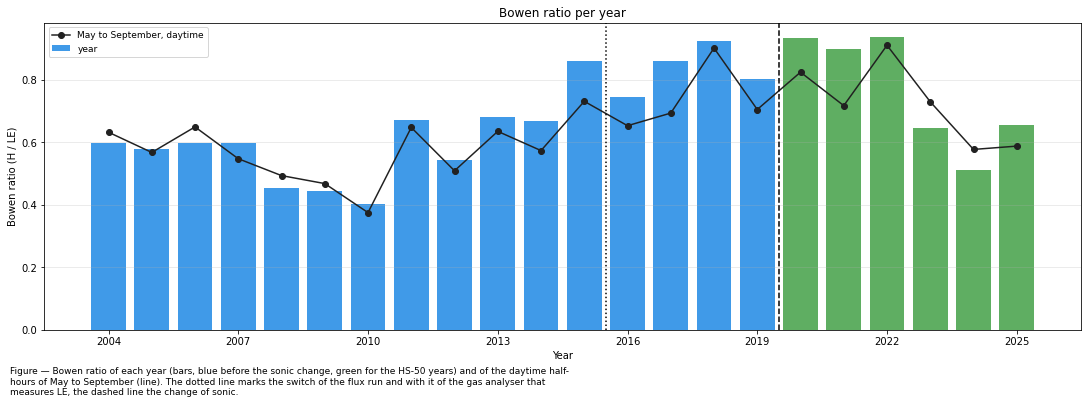

In [28]:
fig, ax = plt.subplots(figsize=(15, 5.5), dpi=72, layout="constrained")
ax.bar(bowen.index, bowen["Bowen ratio, year"], color=bowen['sonic era'].map(ERA_COLORS), alpha=0.85,
       label="year")
ax.plot(bowen.index, bowen["Bowen ratio, May-Sep daytime"], color='#212121', marker='o', lw=1.5,
        label="May to September, daytime")
mark_changes(ax)
ax.set_xlabel("Year")
ax.set_ylabel("Bowen ratio (H / LE)")
ax.set_title("Bowen ratio per year")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, loc='upper left')
year_axis(ax)
figcap(fig, "Bowen ratio of each year (bars, blue before the sonic change, green for the HS-50 years) "
            "and of the daytime half-hours of May to September (line). The dotted line marks the "
            "switch of the flux run and with it of the gas analyser that measures LE, the dashed line "
            "the change of sonic.")
fig.show()

### 📊 Plot: Bowen ratio by year and month

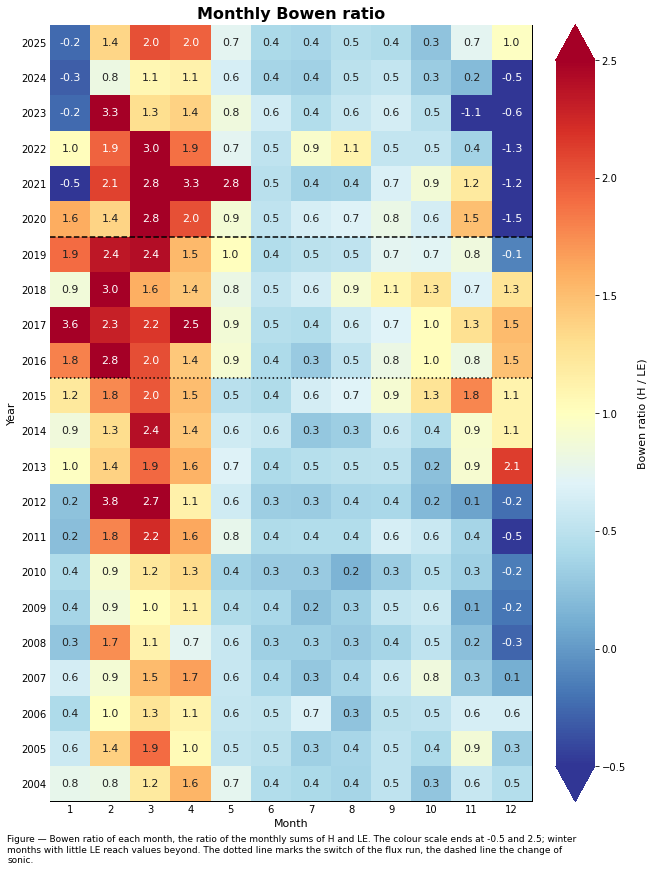

In [29]:
# Ratio of the monthly sums. In winter LE is small and H changes sign, so the ratio becomes large
# or negative; the colour scale is therefore fixed and ends at both sides.
_bm = (per_year_month(series, 'sum', month_names=False)
       / per_year_month(df[lename], 'sum', month_names=False))
_long = _bm.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='RdYlBu_r', vmin=-0.5, vmax=2.5, cb_extend='both', xlabel="Month", ylabel="Year",
    zlabel="Bowen ratio (H / LE)", show_values=True, show_values_n_dec_places=1, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="Monthly Bowen ratio", axlabel_fontsize=11,
                                         ticks_fontsize=10))
mark_changes(ax, horizontal=True)
figcap(fig, "Bowen ratio of each month, the ratio of the monthly sums of H and LE. The colour scale ends "
            "at -0.5 and 2.5; winter months with little LE reach values beyond. The dotted line marks "
            "the switch of the flux run, the dashed line the change of sonic.")

</br>

# The two flux runs in parallel

From 11 January 2016 to 12 December 2017 both flux runs exist, the LI-7500 run and the LI-7200 run.
Both computed `H` from the same sonic anemometer, so their comparison tests the processing, not the
instrument: the settings of each EddyPro run, the water vapour data each run uses for the humidity
correction of the sonic temperature, and the quality tests of each chain. The merged record uses
the LI-7200 run.

In [30]:
_cols = [varname_measured, varname]
par = pd.concat({'IRGA75': pd.read_parquet(Path(DATADIR) / FILE_IRGA75, columns=_cols),
                 'IRGA72': pd.read_parquet(Path(DATADIR) / FILE_IRGA72, columns=_cols)}, axis=1)
par = par.loc[PARALLEL[0]:PARALLEL[1] + ' 23:45']
both = par.xs(varname_measured, axis=1, level=1).dropna()
print(f"Parallel period: {par.index[0]} -> {par.index[-1]} ({len(par):,} half-hours)")
print(f"Both measured:   {len(both):,} half-hours ({100 * len(both) / len(par):.1f} %)")
for _a in ('IRGA75', 'IRGA72'):
    print(f"{_a} measured:     {par[(_a, varname_measured)].notna().mean() * 100:.1f} %")
# The merged record takes H from the LI-7200 run in these years: check that it is that run.
_same = np.allclose(df_full.loc[par.index, varname], par[('IRGA72', varname)])
print(f"Merged H equals the LI-7200 run in the parallel period: {_same}")
assert _same, "the merged record does not take H from the LI-7200 run in 2016-2017"

Parallel period: 2016-01-11 00:15:00 -> 2017-12-12 23:45:00 (33,696 half-hours)
Both measured:   25,079 half-hours (74.4 %)
IRGA75 measured:     74.8 %
IRGA72 measured:     74.8 %
Merged H equals the LI-7200 run in the parallel period: True


## 📋 Table: agreement of the two runs on the half-hours both measured

In [31]:
_d = both['IRGA75'] - both['IRGA72']
_slope, _intercept = np.polyfit(both['IRGA72'], both['IRGA75'], 1)
_rows = {}
for _part, _mask in (("all", slice(None)), ("day", df_full.loc[both.index, DAYTIME].eq(1).to_numpy()),
                     ("night", df_full.loc[both.index, DAYTIME].eq(0).to_numpy())):
    _x = _d[_mask]
    _rows[_part] = {"half-hours": len(_x),
                    "r2": both.loc[_mask, 'IRGA72'].corr(both.loc[_mask, 'IRGA75']) ** 2,
                    f"mean difference ({units})": _x.mean(),
                    f"median difference ({units})": _x.median(),
                    f"median absolute difference ({units})": _x.abs().median(),
                    f"5th percentile ({units})": _x.quantile(0.05),
                    f"95th percentile ({units})": _x.quantile(0.95)}
agreement = pd.DataFrame.from_dict(_rows, orient='index')
agreement.index.name = 'part of day'
display(styled(agreement, caption=f"agreement of H from the LI-7500 run and the LI-7200 run on the "
                                  f"half-hours both measured, {PARALLEL[0]} to {PARALLEL[1]}. The "
                                  f"difference is LI-7500 run minus LI-7200 run; the least-squares "
                                  f"line over all half-hours is LI-7500 = {_slope:.3f} x LI-7200 "
                                  f"{_intercept:+.2f} {units}",
               fmt={"half-hours": "{:.0f}", "r2": "{:.4f}",
                    **{c: "{:+.2f}" for c in agreement.columns if units in c}}, cmap=None))

Table — agreement of H from the LI-7500 run and the LI-7200 run on the half-hours both measured,
2016-01-11 to 2017-12-12. The difference is LI-7500 run minus LI-7200 run; the least-squares line
over all half-hours is LI-7500 = 0.997 x LI-7200 -0.35 W m-2



,half-hours,r2,mean difference (W m-2),median difference (W m-2),median absolute difference (W m-2),5th percentile (W m-2),95th percentile (W m-2)
part of day,,,,,,,
all,25079,0.9965,-0.50,-0.08,+0.46,-5.48,+2.48
day,13592,0.9964,-0.78,-0.04,+0.73,-8.18,+2.80
night,11487,0.9722,-0.15,-0.11,+0.26,-2.54,+1.79


## 📋 Table: means and totals of both runs in the parallel period

In [32]:
_rows = {}
for _label, _s75, _s72 in (
        ("half-hours both measured", both['IRGA75'], both['IRGA72']),
        ("all half-hours, gap-filled", par[('IRGA75', varname)], par[('IRGA72', varname)])):
    for _part, _mask in (("all", None), ("day", True), ("night", False)):
        _m = slice(None) if _mask is None else (df_full.loc[_s75.index, DAYTIME].eq(1) == _mask).to_numpy()
        _a, _b = _s75[_m], _s72[_m]
        _rows[(_label, _part)] = {f"LI-7500 run ({units})": _a.mean(), f"LI-7200 run ({units})": _b.mean(),
                                  f"LI-7500 run ({units_sum})": to_mj(_a), f"LI-7200 run ({units_sum})": to_mj(_b),
                                  f"LI-7500 minus LI-7200 ({units_sum})": to_mj(_a) - to_mj(_b)}
parallel = pd.DataFrame.from_dict(_rows, orient='index')
parallel.index.names = ['records', 'part of day']
display(styled(parallel, caption=f"H of both runs over {PARALLEL[0]} to {PARALLEL[1]}, as means in {units} "
                                 f"and totals in {units_sum}: on the half-hours both measured, and over "
                                 f"all half-hours of each gap-filled record",
               fmt={c: ("{:.1f}" if units in c and units_sum not in c else "{:.0f}")
                    for c in parallel.columns}, subset=[f"LI-7500 minus LI-7200 ({units_sum})"],
               cmap='RdBu_r', center=True))

Table — H of both runs over 2016-01-11 to 2017-12-12, as means in W m-2 and totals in MJ m-2: on the
half-hours both measured, and over all half-hours of each gap-filled record



## 📊 Plot: cumulative H of both runs in the parallel period

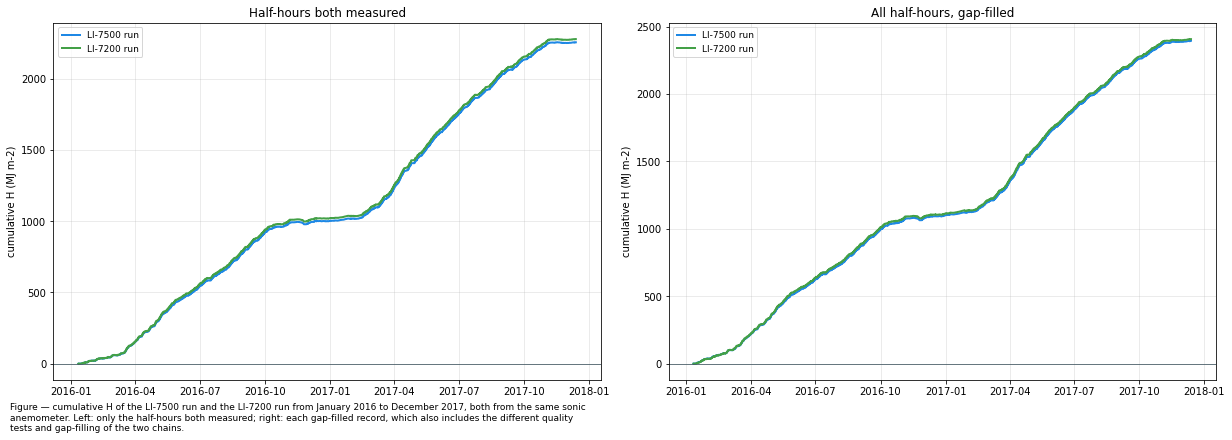

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
for _a, _c, _label in (('IRGA75', '#1E88E5', 'LI-7500 run'), ('IRGA72', '#43A047', 'LI-7200 run')):
    axs[0].plot(both.index, both[_a].cumsum() * WM2_TO_MJ, color=_c, lw=2, label=_label)
    axs[1].plot(par.index, par[(_a, varname)].cumsum() * WM2_TO_MJ, color=_c, lw=2, label=_label)
axs[0].set_title("Half-hours both measured")
axs[1].set_title("All half-hours, gap-filled")
for _ax in axs:
    _ax.set_ylabel(f"cumulative H ({units_sum})")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, "cumulative H of the LI-7500 run and the LI-7200 run from January 2016 to December 2017, "
            "both from the same sonic anemometer. Left: only the half-hours both measured; right: each "
            "gap-filled record, which also includes the different quality tests and gap-filling of "
            "the two chains.")
fig.show()

## 📊 Plot: the two runs half-hour by half-hour

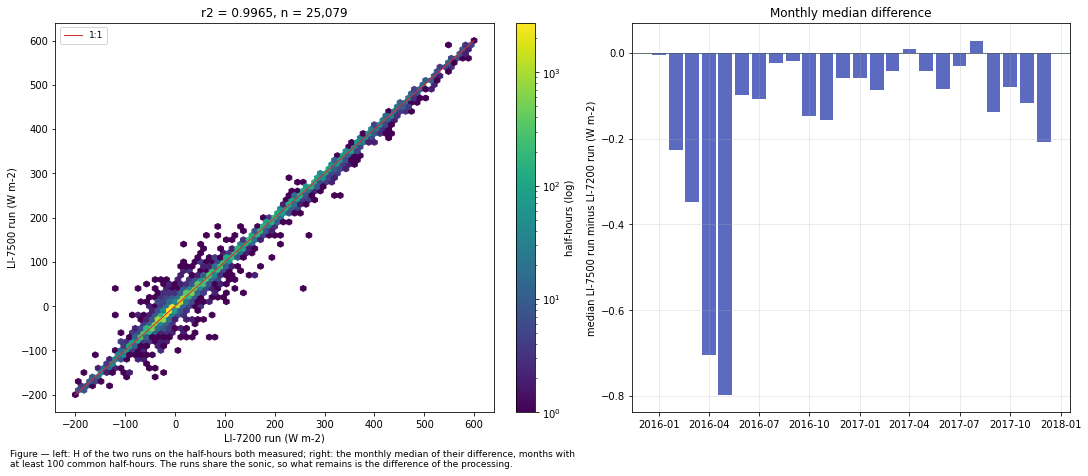

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), dpi=72, layout="constrained")
_ext = (-200, 600, -200, 600)
_hb = axs[0].hexbin(both['IRGA72'], both['IRGA75'], gridsize=70, mincnt=1, bins='log', cmap='viridis',
                    extent=_ext)
axs[0].plot(_ext[:2], _ext[:2], color='#D32F2F', lw=1, label='1:1')
axs[0].set_xlabel(f"LI-7200 run ({units})")
axs[0].set_ylabel(f"LI-7500 run ({units})")
axs[0].set_title(f"r2 = {both['IRGA72'].corr(both['IRGA75']) ** 2:.4f}, n = {len(both):,}")
axs[0].legend(fontsize=9)
fig.colorbar(_hb, ax=axs[0], label="half-hours (log)")
_diff = (both['IRGA75'] - both['IRGA72'])
_m = _diff.groupby(_diff.index.to_period('M')).agg(['median', 'count'])
_m = _m[_m['count'] >= 100]
axs[1].bar(_m.index.to_timestamp(), _m['median'], width=25, color='#5C6BC0')
axs[1].axhline(0, color='#455A64', lw=0.8)
axs[1].set_ylabel(f"median LI-7500 run minus LI-7200 run ({units})")
axs[1].set_title("Monthly median difference")
axs[1].grid(alpha=0.3)
figcap(fig, "left: H of the two runs on the half-hours both measured; right: the monthly median of "
            "their difference, months with at least 100 common half-hours. The runs share the sonic, "
            "so what remains is the difference of the processing.")
fig.show()

</br>

# Heatmap plots

## Half-hourly

### 📊 Plot: heatmap of the half-hourly values

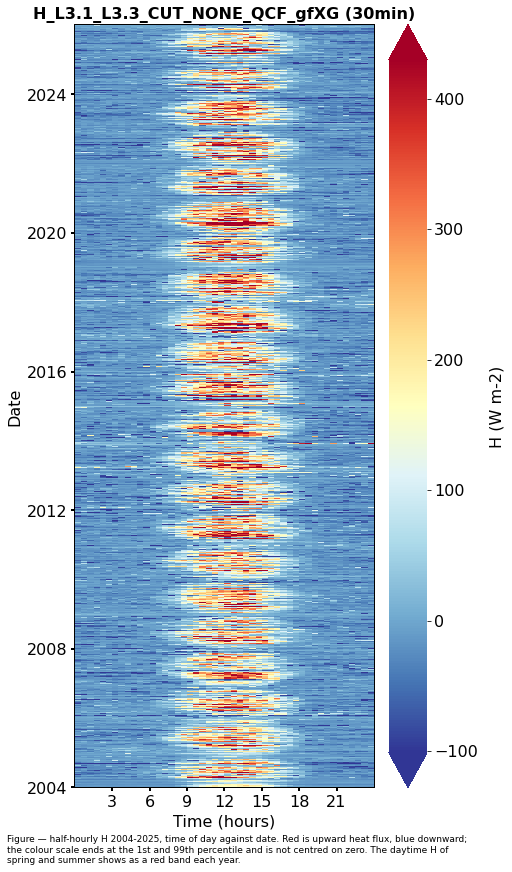

In [35]:
_lo, _hi = series.quantile([0.01, 0.99])
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapDateTime(series=series).plot(ax=ax, cmap='RdYlBu_r', vmin=_lo, vmax=_hi,
                                                cb_extend='both', zlabel=xlabel)
figcap(fig, f"half-hourly H {FIRST_YEAR}-{LAST_YEAR}, time of day against date. Red is upward heat flux, "
            f"blue downward; the colour scale ends at the 1st and 99th percentile and is not centred "
            f"on zero. The daytime H of spring and summer shows as a red band each year.")

## Monthly

### 📊 Plot: monthly means and their ranks

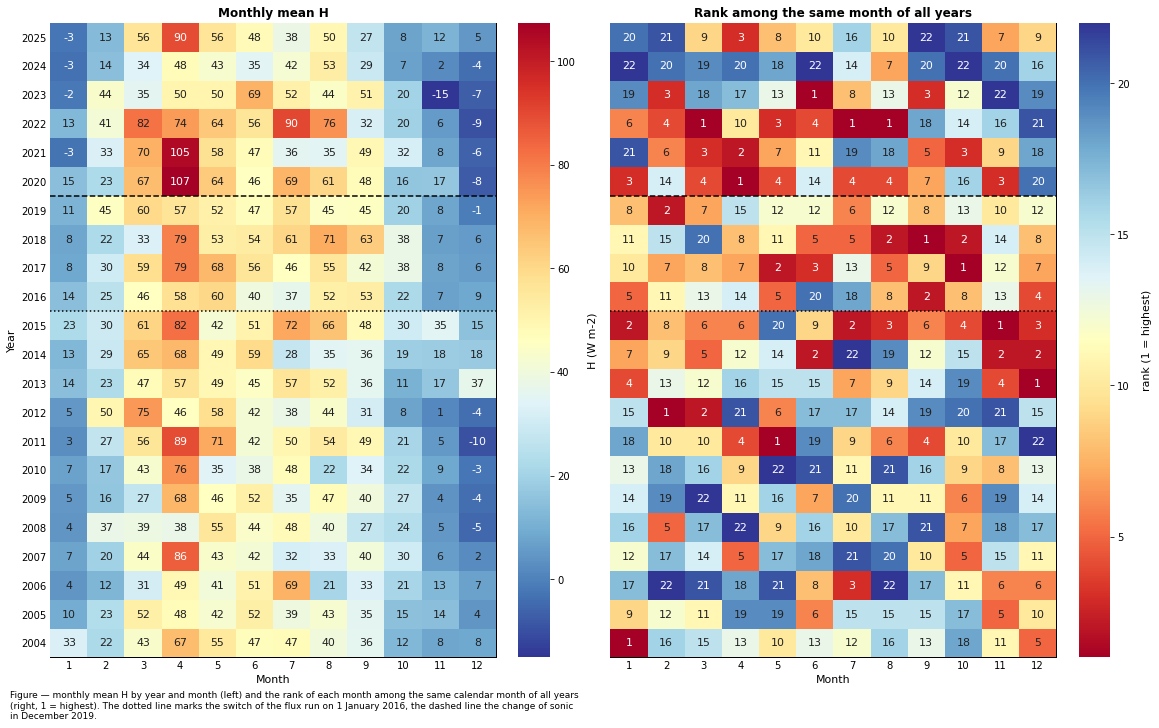

In [36]:
fig, axs = plt.subplots(ncols=2, figsize=(16, 10), dpi=72, sharey=True, layout="constrained")
_style = dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)
_long = monthly_by_number.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=axs[0], cmap='RdYlBu_r', xlabel="Month", ylabel="Year",
    zlabel=f"H ({units})", show_values=True, cb_labelsize=10, format_style=_style)
# Rank 1 is the month of the highest mean among the same calendar month of all years.
_ranks = monthly_by_number.rank(axis=0, ascending=False).stack().rename('z').reset_index()
_ranks.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_ranks['MONTH'], y=_ranks['YEAR'], z=_ranks['z']).plot(
    ax=axs[1], cmap='RdYlBu', xlabel="Month", ylabel="", zlabel="rank (1 = highest)",
    show_values=True, cb_labelsize=10, format_style=_style)
for _ax, _title in zip(axs, ["Monthly mean H", "Rank among the same month of all years"]):
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
    mark_changes(_ax, horizontal=True)
figcap(fig, f"monthly mean H by year and month (left) and the rank of each month among the same "
            f"calendar month of all years (right, 1 = highest). The dotted line marks the switch of "
            f"the flux run on 1 January 2016, the dashed line the change of sonic in December 2019.")

## Anomaly by year and month

### 📊 Plot: anomaly by year and month

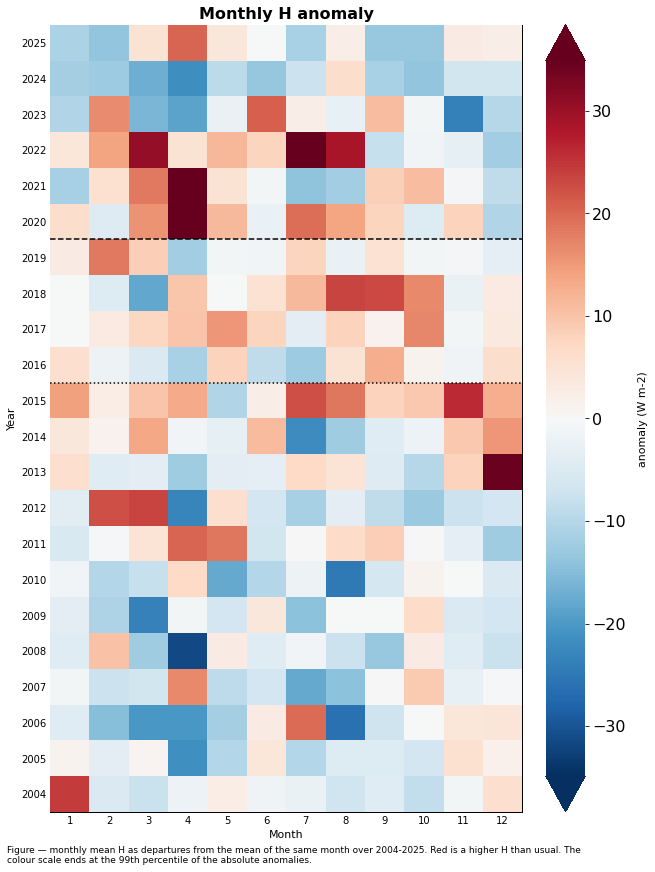

In [37]:
_anom = monthly_by_number - monthly_by_number.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_long = _anom.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, cb_extend='both', xlabel="Month", ylabel="Year",
    zlabel=f"anomaly ({units})",
    format_style=dv.plotting.FormatStyle(title=f"Monthly {var} anomaly", axlabel_fontsize=11, ticks_fontsize=10))
mark_changes(ax, horizontal=True)
figcap(fig, f"monthly mean H as departures from the mean of the same month over "
            f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Red is a higher H than usual. The colour "
            f"scale ends at the 99th percentile of the absolute anomalies.")

</br>

# Anomalies and trends

## Per year

### 📊 Plot: yearly anomalies

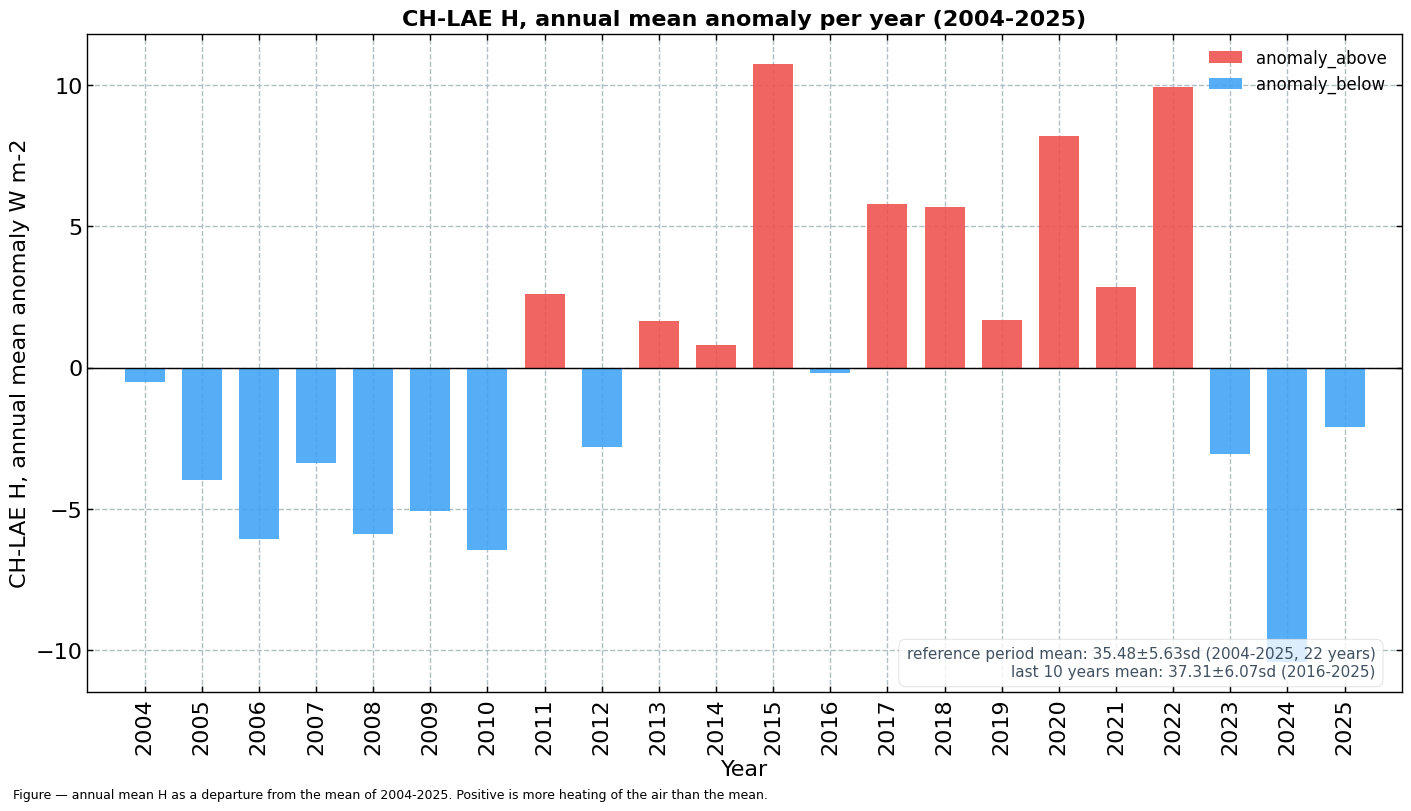

In [38]:
_anomalies_year = LongtermAnomaliesYear(series=ym.rename(varname),
                                        series_label=f"CH-LAE {var}, annual mean",  # the column name is too long for the axis label
                                        series_units=units,
                                        reference_start_year=REFERENCE_START_YEAR,
                                        reference_end_year=REFERENCE_END_YEAR)
_anomalies_year.plot()
figcap(_anomalies_year.fig,
       f"annual mean H as a departure from the mean of {REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. "
       f"Positive is more heating of the air than the mean.")

## Trends

A trend over the whole record crosses the switch of the flux run and the change of sonic. It is
therefore given three ways: over all years, over the years before the sonic change alone, and with
a step at the sonic change removed, so that a trend carried by the step alone can be told apart.

### 📋 Table: trends of the annual values

In [39]:
def _trend_row(s):
    _fit = trend(s.dropna())
    return {"trend per decade": _fit['slope'], "lower 95 %": _fit['low'], "upper 95 %": _fit['high'],
            "p": _fit['pvalue'], "years": int(s.notna().sum())}


_series = {f"annual mean H ({units})": annual[f"H ({units})"],
           f"Jun-Aug mean H ({units})": annual[f"Jun-Aug ({units})"],
           f"annual total H ({units_sum})": annual[f"H total ({units_sum})"],
           "Bowen ratio, year": bowen["Bowen ratio, year"]}
_era = pd.Series([era(y) for y in annual.index], index=annual.index)
_rows = {}
for _c, _s in _series.items():
    _rows[(_c, f"all years, {FIRST_YEAR}-{LAST_YEAR}")] = _trend_row(_s)
    _rows[(_c, f"before the sonic change, {FIRST_YEAR}-{SONIC_CHANGE_YEAR - 1}")] = _trend_row(
        _s.loc[:SONIC_CHANGE_YEAR - 1])
    _rows[(_c, "all years, step at the sonic change removed")] = _trend_row(
        _s - _s.groupby(_era).transform('mean') + _s.mean())
trends = pd.DataFrame.from_dict(_rows, orient='index')
trends.index.names = ['quantity', 'years']
display(styled(trends, caption="Theil-Sen trends per decade of the annual values, in the units of each "
                               "quantity, with their 95 % interval and Kendall p. Removing the step "
                               "subtracts the mean of each sonic era, so only the trend within the eras "
                               "remains",
               fmt={c: ("{:.4f}" if c == "p" else "{:.0f}" if c == "years" else "{:+.2f}") for c in trends.columns},
               cmap=None))

Table — Theil-Sen trends per decade of the annual values, in the units of each quantity, with their
95 % interval and Kendall p. Removing the step subtracts the mean of each sonic era, so only the
trend within the eras remains



### 📊 Plot: annual means and their trends

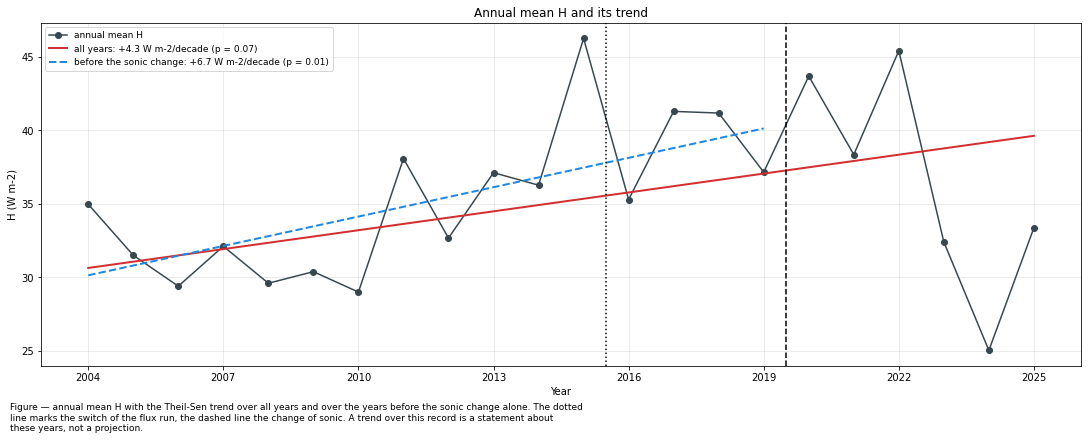

In [40]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.plot(ym.index, ym, marker='o', color='#37474F', lw=1.5, label="annual mean H")
_fit = trend(ym)
ax.plot(_fit['fit'].index, _fit['fit'], color='#D32F2F', lw=2,
        label=f"all years: {_fit['slope']:+.1f} {units}/decade (p = {_fit['pvalue']:.2f})")
_fitb = trend(ym.loc[:SONIC_CHANGE_YEAR - 1])
ax.plot(_fitb['fit'].index, _fitb['fit'], color='#1E88E5', lw=2, ls='--',
        label=f"before the sonic change: {_fitb['slope']:+.1f} {units}/decade (p = {_fitb['pvalue']:.2f})")
mark_changes(ax)
ax.set_xlabel("Year")
ax.set_ylabel(f"H ({units})")
ax.set_title("Annual mean H and its trend")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
year_axis(ax)
figcap(fig, "annual mean H with the Theil-Sen trend over all years and over the years before the sonic "
            "change alone. The dotted line marks the switch of the flux run, the dashed line the "
            "change of sonic. A trend over this record is a statement about these years, not a "
            "projection.")
fig.show()

</br>

# Cumulative plot

## 📊 Plot: cumulative H per year

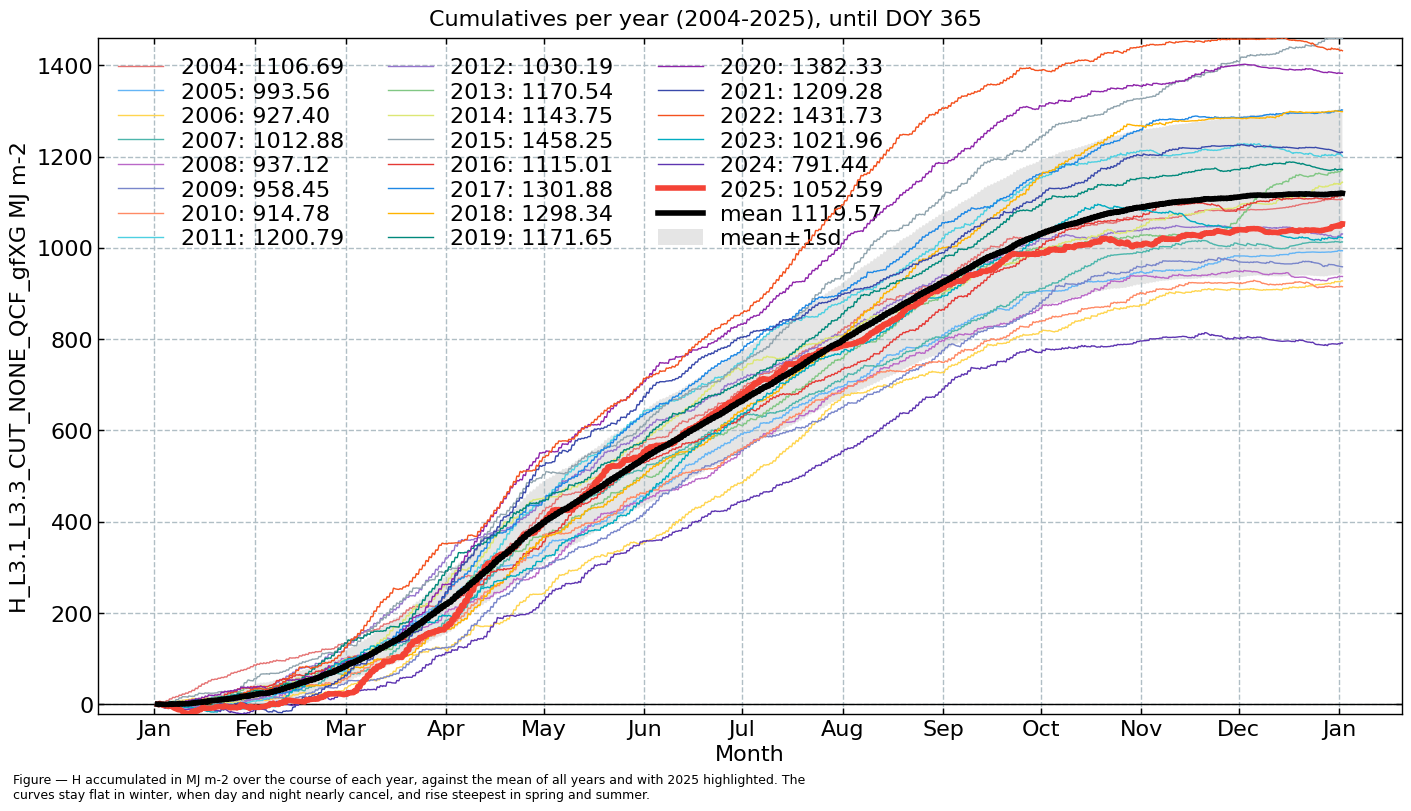

In [41]:
_cumulative = CumulativeYear(
    series=(series * WM2_TO_MJ).rename(varname),
    series_units=units_sum,
    start_year=FIRST_YEAR,
    end_year=LAST_YEAR,
    show_reference=True,
    excl_years_from_reference=None,
    highlight_year=LAST_YEAR)
_cumulative.plot(highlight_year_color='#F44336')
figcap(_cumulative.fig,
       f"H accumulated in {units_sum} over the course of each year, against the mean of all years and "
       f"with {LAST_YEAR} highlighted. The curves stay flat in winter, when day and night nearly "
       f"cancel, and rise steepest in spring and summer.")

</br>

# Distributions

## 📊 Plot: distribution per year

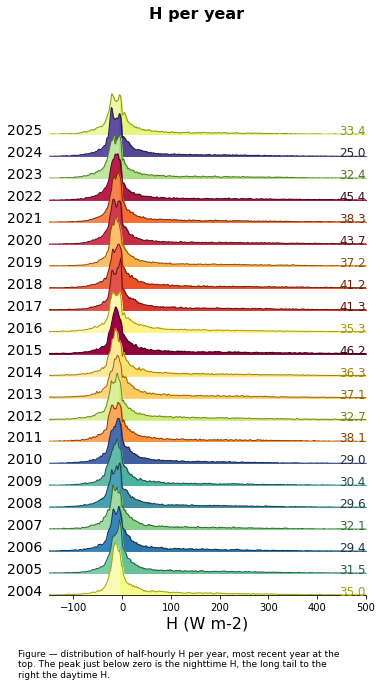

In [42]:
rp = dv.plotting.RidgeLinePlot(series=series)
rp.plot(
    how='yearly',
    kd_kwargs=None,  # params from scikit KernelDensity as dict
    xlim=[-150, 500],  # min/max as list
    ylim=[0, 0.045],  # min/max as list
    hspace=-0.8,  # overlap between years
    fig_width=5,
    fig_height=9,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=xlabel, title=f"{var} per year"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
# RidgeLinePlot places the year and mean labels at a density of 0.01 instead of at the baseline of
# each curve. The densities of H are small, so this lifts every label by about a row; the labels
# are moved to the baseline here.
for _ax in rp.fig.axes:
    for _t in _ax.texts:
        _t.set_y(0)
figcap(rp.fig, f"distribution of half-hourly H per year, most recent year at the top. The peak just "
               f"below zero is the nighttime H, the long tail to the right the daytime H.")

</br>

# End of notebook

In [43]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
_runtime = datetime.now() - NOTEBOOK_START
print(f"Finished. {dt_string}")
print(f"Runtime: {_runtime.total_seconds() / 60:.1f} minutes")

Finished. 2026-10-30 22:10:03
Runtime: 0.3 minutes
